In [48]:
from google.colab import files

uploaded = files.upload()

Saving Netflix_EDA_Corrected_Charts.pdf to Netflix_EDA_Corrected_Charts (1).pdf


In [49]:
import pandas as pd
import os

# Load the nine cleaned datasets
cleaned_datasets = {
    "customers": pd.read_csv("/content/customers.csv"),
    "subscriptions": pd.read_csv("/content/subscriptions.csv"),
    "subscription_plans": pd.read_csv("/content/subscription_plans (1).csv"),
    "viewing_activity": pd.read_csv("/content/viewing_activity (1).csv"),
    "support_tickets": pd.read_csv("/content/support_tickets.csv"),
    "payments": pd.read_csv("/content/payments.csv"),
    "churn_labels": pd.read_csv("/content/churn_labels (1).csv"),
    "customer_feedback": pd.read_csv("/content/customer_feedback.csv"),
    "content": pd.read_csv("/content/content (1).csv")
}

# Display dataset information
print("ALL CLEANED DATASETS LOADED SUCCESSFULLY\n")

for name, df in cleaned_datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

print("\nTotal datasets:", len(cleaned_datasets))

ALL CLEANED DATASETS LOADED SUCCESSFULLY

customers: 8,000 rows × 12 columns
subscriptions: 8,875 rows × 13 columns
subscription_plans: 3 rows × 6 columns
viewing_activity: 66,422 rows × 11 columns
support_tickets: 6,120 rows × 11 columns
payments: 110,735 rows × 7 columns
churn_labels: 8,000 rows × 4 columns
customer_feedback: 5,046 rows × 11 columns
content: 500 rows × 9 columns

Total datasets: 9


# PHASE 3: EXPLORATORY DATA ANALYSIS (EDA)

## 1. Introduction

Exploratory Data Analysis (EDA) is performed to understand the structure, characteristics, distributions, and relationships within the cleaned Netflix datasets.

This phase focuses on identifying customer behaviour patterns, subscription trends, viewing preferences, payment behaviour, customer support experiences, feedback patterns, and factors associated with customer churn.

The analysis uses the nine cleaned datasets prepared during Phase 2: Data Cleaning and Preprocessing.

## 2. Objectives

- Understand the distribution and characteristics of each dataset.
- Analyse customer demographics and subscription patterns.
- Explore viewing activity, content preferences, and engagement.
- Examine payment behaviour and subscription revenue patterns.
- Evaluate customer support interactions and feedback.
- Investigate customer churn patterns and potential contributing factors.
- Identify meaningful relationships and business trends.
- Generate actionable insights to support subsequent feature engineering and machine-learning development.

## 3. Scope of Analysis

The EDA phase covers the following nine datasets:

1. Customers
2. Subscriptions
3. Subscription Plans
4. Viewing Activity
5. Support Tickets
6. Payments
7. Churn Labels
8. Customer Feedback
9. Content

## 4. Expected Outcome

The outcome of this phase will be a structured understanding of the Netflix customer dataset, supported by statistical summaries, visualisations, relationship analysis, and business insights.

These findings will guide feature engineering, churn prediction, customer segmentation, and customer lifetime value modelling in subsequent project phases.

In [50]:
# Display the structure of all nine datasets

for name, df in cleaned_datasets.items():
    print("\n" + "=" * 65)
    print(f"DATASET: {name.upper()}")
    print("=" * 65)

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("Data types:")
    print(df.dtypes)


DATASET: CUSTOMERS
Shape: (8000, 12)
Columns: ['customer_id', 'first_name', 'last_name', 'age', 'gender', 'country', 'city', 'registration_date', 'acquisition_channel', 'customer_segment', 'preferred_language', 'age_validation_flag']
Data types:
customer_id             object
first_name              object
last_name               object
age                    float64
gender                  object
country                 object
city                    object
registration_date       object
acquisition_channel     object
customer_segment        object
preferred_language      object
age_validation_flag     object
dtype: object

DATASET: SUBSCRIPTIONS
Shape: (8875, 13)
Columns: ['subscription_id', 'customer_id', 'plan_id', 'subscription_start_date', 'subscription_end_date', 'subscription_status', 'auto_renew', 'cancellation_date', 'cancellation_reason', 'monthly_price', 'cancellation_date_flag', 'validated_cancellation_date', 'price_validation_flag']
Data types:
subscription_id           

## 5. Data Type Preparation

Before performing time-based exploratory analysis, date columns stored as text must be converted into appropriate datetime formats.

This preparation will support:
- Customer registration trend analysis.
- Subscription start and cancellation trend analysis.
- Viewing activity over time.
- Payment trend analysis.
- Customer support ticket trends.
- Feedback and churn timeline analysis.

The date conversion will be performed on the loaded dataset copies. The original CSV files will remain unchanged.

Invalid or unparseable date values will be converted to missing datetime values using error handling, allowing them to be identified and investigated.

In [51]:
# Define date columns for each dataset

date_columns = {
    "customers": ["registration_date"],
    "subscriptions": [
        "subscription_start_date",
        "subscription_end_date",
        "cancellation_date",
        "validated_cancellation_date"
    ],
    "viewing_activity": ["viewing_date"],
    "support_tickets": ["ticket_date"],
    "payments": ["payment_date"],
    "churn_labels": ["churn_date"],
    "customer_feedback": ["feedback_date"]
}

# Convert date columns to datetime format

for dataset_name, columns in date_columns.items():
    for column in columns:
        cleaned_datasets[dataset_name][column] = pd.to_datetime(
            cleaned_datasets[dataset_name][column],
            errors="coerce"
        )

print("Date conversion completed.")

Date conversion completed.


In [52]:
for dataset_name, columns in date_columns.items():

    print("\n" + "=" * 55)
    print(dataset_name.upper())
    print("=" * 55)

    df = cleaned_datasets[dataset_name]

    for column in columns:
        print(f"\nColumn: {column}")
        print("Data type:", df[column].dtype)
        print("Missing dates:", df[column].isna().sum())

        valid_dates = df[column].dropna()

        if not valid_dates.empty:
            print("Earliest date:", valid_dates.min())
            print("Latest date:", valid_dates.max())


CUSTOMERS

Column: registration_date
Data type: datetime64[ns]
Missing dates: 0
Earliest date: 2019-01-01 00:00:00
Latest date: 2026-05-31 00:00:00

SUBSCRIPTIONS

Column: subscription_start_date
Data type: datetime64[ns]
Missing dates: 0
Earliest date: 2019-01-01 00:00:00
Latest date: 2026-06-29 00:00:00

Column: subscription_end_date
Data type: datetime64[ns]
Missing dates: 8000
Earliest date: 2019-04-11 00:00:00
Latest date: 2026-06-29 00:00:00

Column: cancellation_date
Data type: datetime64[ns]
Missing dates: 6884
Earliest date: 2025-10-03 00:00:00
Latest date: 2026-06-30 00:00:00

Column: validated_cancellation_date
Data type: datetime64[ns]
Missing dates: 6926
Earliest date: 2025-10-03 00:00:00
Latest date: 2026-06-30 00:00:00

VIEWING_ACTIVITY

Column: viewing_date
Data type: datetime64[ns]
Missing dates: 0
Earliest date: 2025-07-01 00:00:00
Latest date: 2026-06-30 00:00:00

SUPPORT_TICKETS

Column: ticket_date
Data type: datetime64[ns]
Missing dates: 61
Earliest date: 2019-03

### 5.3 Date Conversion Results

Date columns across seven datasets were successfully converted into datetime format.

The analysis identified the following observations:

- Customer registration dates range from January 2019 to May 2026.
- Subscription start dates range from January 2019 to June 2026.
- Viewing activity dates cover July 2025 to June 2026.
- Payment dates range from January 2019 to May 2026.
- Customer feedback dates range from March 2019 to June 2026.
- Support tickets contain 61 missing dates resulting from invalid date values identified during preprocessing.
- Subscription end dates, cancellation dates, and churn dates contain missing values that must be interpreted according to subscription and churn status.

No artificial date values were introduced. The converted dates will support time-based analysis in subsequent EDA sections.

## 6. Statistical Overview

Descriptive statistical analysis is performed to understand the numerical characteristics of the cleaned datasets.

The analysis includes:
- Count of available numerical observations.
- Mean and median values.
- Standard deviation and data variability.
- Minimum and maximum values.
- Quartiles and distribution ranges.

This step helps identify general patterns, variation, and potential extreme values before conducting detailed visual and relationship analysis.

Numerical statistics will be calculated separately for each dataset to maintain clarity and support dataset-specific interpretation.

In [53]:
# Generate descriptive statistics for all datasets

for name, df in cleaned_datasets.items():

    print("\n" + "=" * 70)
    print(f"STATISTICAL SUMMARY: {name.upper()}")
    print("=" * 70)

    numerical_df = df.select_dtypes(include=["number"])

    if numerical_df.empty:
        print("No numerical columns available.")
    else:
        display(numerical_df.describe().round(2))


STATISTICAL SUMMARY: CUSTOMERS


,age
count,7671.00
mean,32.56
std,10.75
min,2.00
25%,25.00
50%,32.00
75%,40.00
max,76.00



STATISTICAL SUMMARY: SUBSCRIPTIONS


,monthly_price
count,8875.00
mean,13.45
std,6.14
min,6.99
25%,6.99
50%,15.49
75%,15.49
max,22.99



STATISTICAL SUMMARY: SUBSCRIPTION_PLANS


,monthly_price,max_devices
count,3.00,3.00
mean,15.16,2.33
std,8.01,1.53
min,6.99,1.00
25%,11.24,1.50
50%,15.49,2.00
75%,19.24,3.00
max,22.99,4.00


... (6 outputs left out)


STATISTICAL SUMMARY: CHURN_LABELS
No numerical columns available.

STATISTICAL SUMMARY: CUSTOMER_FEEDBACK


,rating,feedback_text_length,feedback_year
count,5046.00,5046.00,5046.00
mean,3.16,87.95,2024.12
std,1.29,4.34,1.68
min,1.00,81.00,2019.00
25%,2.00,85.00,2023.00
50%,3.00,88.00,2025.00
75%,4.00,91.00,2025.00
max,5.00,97.00,2026.00



STATISTICAL SUMMARY: CONTENT


,release_year,duration_minutes
count,500.00,500.00
mean,2012.03,69.57
std,8.23,35.75
min,1998.00,20.00
25%,2005.00,37.75
50%,2012.00,66.00
75%,2020.00,102.00
max,2026.00,166.00


### 6.1 Statistical Analysis Findings

Descriptive statistics were generated for the numerical columns across all nine datasets.

The analysis identified the following findings:

- The average customer age is approximately 32.56 years.
- Subscription monthly prices range from 6.99 to 22.99.
- Average watch duration is 49.43 minutes, with an average completion percentage of 70.47%.
- Support tickets with available resolution information have an average resolution time of 18 hours.
- The average customer satisfaction score is 3.26 out of 5.
- The average payment amount is 13.75, while the median is 15.49.
- Customer feedback has an average rating of 3.16 out of 5.
- The content catalogue has an average recorded duration of 69.57 minutes.

Further investigation is required for unusual viewing-duration gaps, extreme payment amounts, age-validation cases, and differences across content types.

Missing values were not automatically filled or removed. Their business meaning will be considered during subsequent analysis.

These findings provide an initial understanding of the numerical characteristics of the datasets and help identify areas requiring deeper investigation.

## 7. Categorical Data Analysis

Categorical analysis examines the frequency and distribution of non-numerical variables across the nine datasets.

The analysis will help identify:

- Customer demographic categories and acquisition channels.
- Subscription status and auto-renewal patterns.
- Viewing device preferences.
- Support ticket categories, priorities, and statuses.
- Payment methods and transaction statuses.
- Churn and non-churn customer distribution.
- Customer feedback sentiment and rating categories.
- Content types, genres, languages, and maturity ratings.

Frequency counts and percentage distributions will be used to understand the composition of each category and identify dominant patterns.

In [54]:
# Categorical frequency analysis

categorical_columns = {
    "customers": [
        "gender",
        "country",
        "acquisition_channel",
        "customer_segment",
        "preferred_language"
    ],
    "subscriptions": [
        "subscription_status",
        "auto_renew",
        "cancellation_reason"
    ],
    "subscription_plans": [
        "plan_name",
        "video_quality",
        "advertisements"
    ],
    "viewing_activity": [
        "device_type",
        "login_location",
        "duration_mismatch_category"
    ],
    "support_tickets": [
        "issue_category",
        "priority",
        "ticket_status"
    ],
    "payments": [
        "payment_method",
        "payment_status",
        "failed_payment_reason"
    ],
    "churn_labels": [
        "churned",
        "churn_reason"
    ],
    "customer_feedback": [
        "rating",
        "sentiment_label",
        "sentiment_match"
    ],
    "content": [
        "content_type",
        "genre",
        "content_language",
        "production_country",
        "maturity_rating"
    ]
}

for dataset_name, columns in categorical_columns.items():

    df = cleaned_datasets[dataset_name]

    for column in columns:

        print("\n" + "=" * 65)
        print(f"{dataset_name.upper()} — {column.upper()}")
        print("=" * 65)

        counts = df[column].value_counts(dropna=False)

        percentages = (
            df[column]
            .value_counts(normalize=True, dropna=False)
            .mul(100)
            .round(2)
        )

        summary = pd.DataFrame({
            "Count": counts,
            "Percentage": percentages
        })

        display(summary)


CUSTOMERS — GENDER


,Count,Percentage
gender,,
Female,3817,47.71
Male,3779,47.24
Other,247,3.09
Prefer not to say,157,1.96



CUSTOMERS — COUNTRY


,Count,Percentage
country,,
United States,1449,18.11
India,1251,15.64
United Kingdom,613,7.66
Canada,419,5.24
NaN,409,5.11
Brazil,380,4.75
Germany,378,4.72
France,314,3.92
Mexico,299,3.74



CUSTOMERS — ACQUISITION_CHANNEL


,Count,Percentage
acquisition_channel,,
Organic Search,1786,22.32
Paid Social,1427,17.84
Referral,1081,13.51
App Store,990,12.38
Affiliate Partner,793,9.91
Email Campaign,785,9.81
Partner Bundle (Telecom),640,8.00
Direct,498,6.22


... (50 outputs left out)


CONTENT — PRODUCTION_COUNTRY


,Count,Percentage
production_country,,
India,96,19.2
United States,92,18.4
United Kingdom,30,6.0
Germany,29,5.8
France,25,5.0
Canada,22,4.4
Brazil,21,4.2
Japan,20,4.0
South Korea,20,4.0



CONTENT — MATURITY_RATING


,Count,Percentage
maturity_rating,,
PG-13,81,16.2
NR,77,15.4
TV-14,76,15.2
TV-MA,70,14.0
R,69,13.8
PG,67,13.4
G,60,12.0


### 7.1 Categorical Analysis Findings

Categorical frequency and percentage analysis was performed across all nine datasets.

Key observations include:

- Female and male customers represent 47.71% and 47.24% of recorded customer records, respectively.
- The United States and India are the two largest customer markets.
- Organic Search is the leading acquisition channel, accounting for 22.32% of customers.
- Individual customers represent 54.82% of customer segments.
- Active subscriptions account for 67.71% of subscription records.
- Auto-renewal is enabled in 81.43% of subscription records.
- Smart TVs account for 37.84% of viewing activity records.
- Billing & Payments is the most common support issue category at 27.92%.
- Successful payments represent 93.49% of payment transactions.
- The customer churn rate is 24.89%.
- Positive feedback represents 39.20% of feedback records.
- Movies account for 43.20% of the available content catalogue.

Additional analysis identified subscription affordability and alternative streaming platforms as the two most frequently recorded cancellation reasons.

Missing categorical values were retained and interpreted according to their business context. Subscription plan frequencies were treated as reference information rather than customer distribution.

These findings provide an initial understanding of customer composition, engagement channels, operational issues, and churn distribution.

## 8. Univariate Data Visualisation

Univariate analysis examines individual variables independently to understand their distributions and identify dominant patterns.

Histograms will be used for numerical variables, while bar charts will be used for categorical variables.

The visualisations will cover customer demographics, subscription status, viewing behaviour, payment outcomes, customer feedback, and content composition.

The purpose is to complement descriptive statistics and categorical frequency analysis with visual representations that make patterns easier to identify.

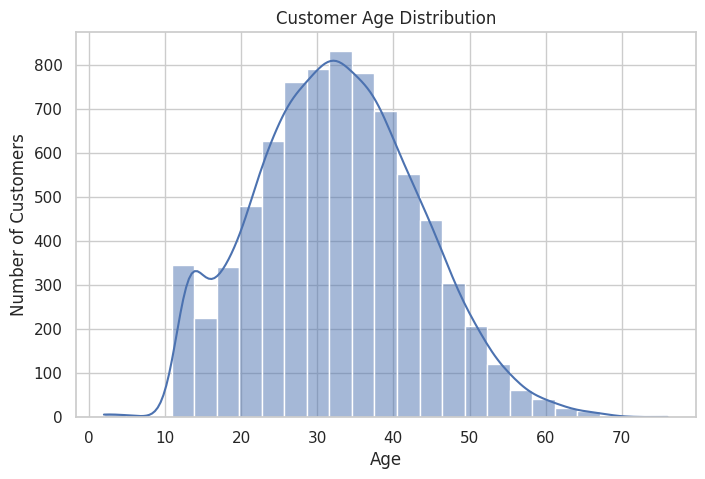

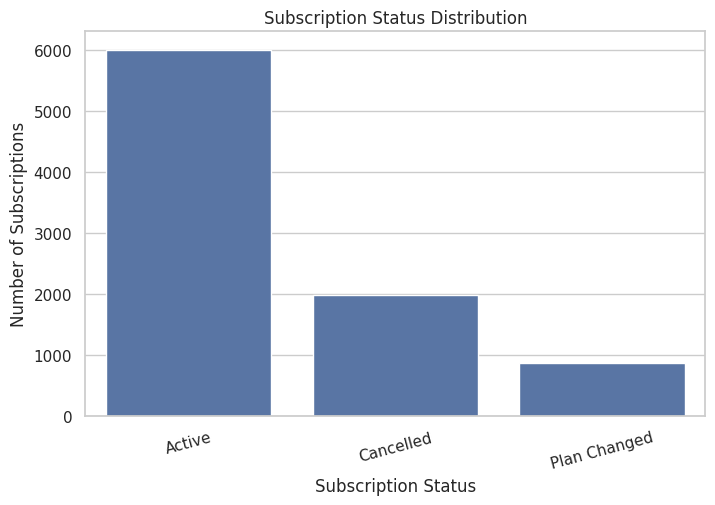

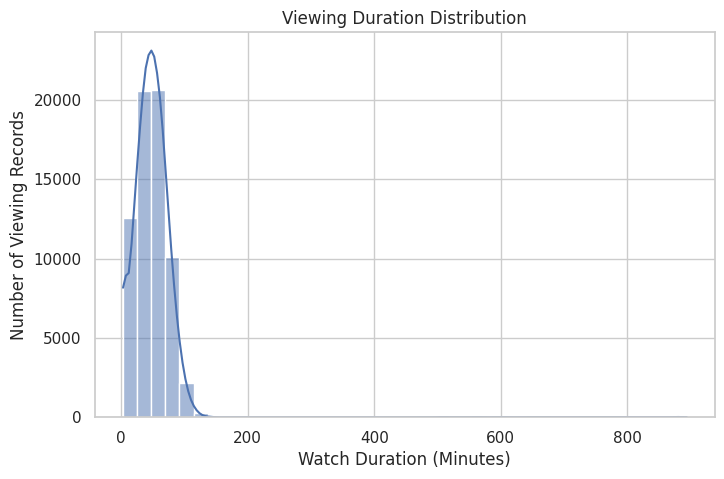

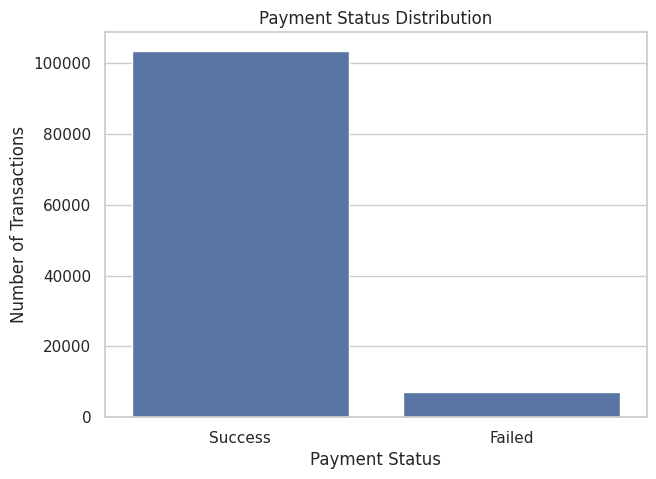

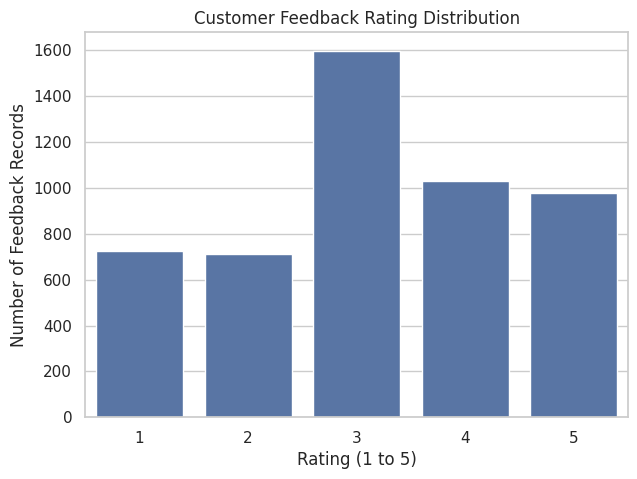

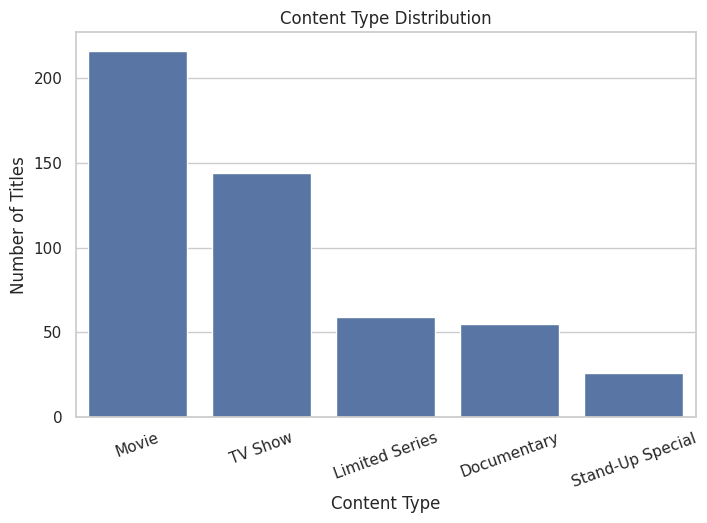

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Customer Age Distribution
plt.figure(figsize=(8, 5))
sns.histplot(
    data=cleaned_datasets["customers"],
    x="age",
    bins=25,
    kde=True
)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()


# 2. Subscription Status Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=cleaned_datasets["subscriptions"],
    x="subscription_status",
    order=cleaned_datasets["subscriptions"]["subscription_status"].value_counts().index
)
plt.title("Subscription Status Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Subscriptions")
plt.xticks(rotation=15)
plt.show()


# 3. Viewing Duration Distribution
plt.figure(figsize=(8, 5))
sns.histplot(
    data=cleaned_datasets["viewing_activity"],
    x="watch_duration_minutes",
    bins=40,
    kde=True
)
plt.title("Viewing Duration Distribution")
plt.xlabel("Watch Duration (Minutes)")
plt.ylabel("Number of Viewing Records")
plt.show()


# 4. Payment Status Distribution
plt.figure(figsize=(7, 5))
sns.countplot(
    data=cleaned_datasets["payments"],
    x="payment_status",
    order=cleaned_datasets["payments"]["payment_status"].value_counts().index
)
plt.title("Payment Status Distribution")
plt.xlabel("Payment Status")
plt.ylabel("Number of Transactions")
plt.show()


# 5. Customer Feedback Rating Distribution
plt.figure(figsize=(7, 5))
sns.countplot(
    data=cleaned_datasets["customer_feedback"],
    x="rating",
    order=sorted(cleaned_datasets["customer_feedback"]["rating"].unique())
)
plt.title("Customer Feedback Rating Distribution")
plt.xlabel("Rating (1 to 5)")
plt.ylabel("Number of Feedback Records")
plt.show()


# 6. Content Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=cleaned_datasets["content"],
    x="content_type",
    order=cleaned_datasets["content"]["content_type"].value_counts().index
)
plt.title("Content Type Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=20)
plt.show()

In [56]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

with PdfPages("Netflix_EDA_Charts.pdf") as pdf:

    charts = [
        ("customers", "age", "Customer Age Distribution", "hist"),
        ("subscriptions", "subscription_status", "Subscription Status Distribution", "count"),
        ("viewing_activity", "watch_duration_minutes", "Viewing Duration Distribution", "hist"),
        ("payments", "payment_status", "Payment Status Distribution", "count"),
        ("customer_feedback", "rating", "Customer Feedback Rating Distribution", "count"),
        ("content", "content_type", "Content Type Distribution", "count")
    ]

    for dataset, column, title, chart_type in charts:
        plt.figure(figsize=(9, 5))

        if chart_type == "hist":
            sns.histplot(data=cleaned_datasets[dataset], x=column, bins=30, kde=True)
        else:
            sns.countplot(
                data=cleaned_datasets[dataset],
                x=column,
                order=cleaned_datasets[dataset][column].value_counts().index
            )

        plt.title(title)
        plt.xticks(rotation=20)
        plt.tight_layout()
        pdf.savefig()
        plt.close()

print("PDF created successfully!")

PDF created successfully!


## 9.1 Interpretation of Univariate Visualisations

The univariate visualisations helped understand the distribution of important numerical and categorical variables across the Netflix datasets.

### Key Observations

1. **Customer Age:** Most customers belong to the approximately 20–45 age group, with the distribution peaking around the early 30s.

2. **Subscription Status:** Active subscriptions represent 67.71% of subscription records, followed by cancelled subscriptions at 22.43% and plan changes at 9.86%.

3. **Viewing Duration:** Most viewing sessions have relatively short durations. The distribution is right-skewed due to a small number of unusually long viewing records.

4. **Payment Status:** Approximately 93.49% of payment transactions were successful, while 6.51% failed.

5. **Customer Feedback:** Rating 3 is the most frequent rating, representing 31.69% of feedback records. Both positive and negative ratings are also present.

6. **Content Type:** Movies represent the largest content category at 43.2%, followed by TV Shows at 28.8%.

### Overall Findings

The visualisations provide an initial understanding of customer demographics, subscription behaviour, viewing patterns, payment performance, customer feedback and content distribution.

These observations will help guide further analysis, including customer churn investigation, customer segmentation and predictive modelling.

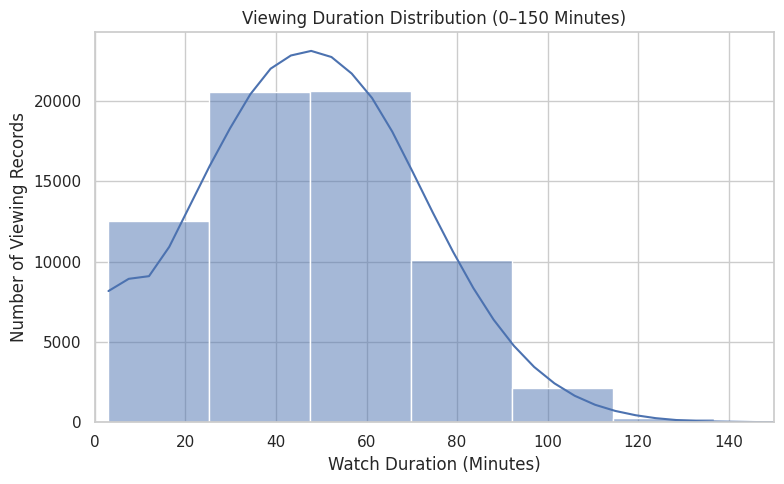

Minimum viewing duration: 3
Maximum viewing duration: 894


In [57]:
# Viewing Duration Distribution (Zoomed View)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=cleaned_datasets["viewing_activity"],
    x="watch_duration_minutes",
    bins=40,
    kde=True
)

plt.xlim(0, 150)
plt.title("Viewing Duration Distribution (0–150 Minutes)")
plt.xlabel("Watch Duration (Minutes)")
plt.ylabel("Number of Viewing Records")
plt.tight_layout()
plt.show()

# Display the full range separately
print("Minimum viewing duration:",
      cleaned_datasets["viewing_activity"]["watch_duration_minutes"].min())

print("Maximum viewing duration:",
      cleaned_datasets["viewing_activity"]["watch_duration_minutes"].max())

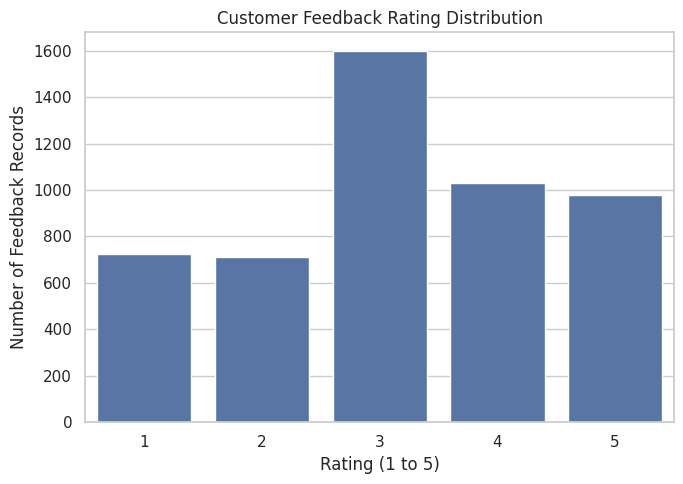

In [58]:
# Customer Feedback Rating Distribution (Correct Numerical Order)

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=cleaned_datasets["customer_feedback"],
    x="rating",
    order=[1, 2, 3, 4, 5]
)

plt.title("Customer Feedback Rating Distribution")
plt.xlabel("Rating (1 to 5)")
plt.ylabel("Number of Feedback Records")

plt.tight_layout()
plt.show()

In [59]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

with PdfPages("/content/Netflix_EDA_Corrected_Charts.pdf") as pdf:

    # Chart 1: Viewing Duration
    plt.figure(figsize=(9, 5))
    sns.histplot(
        data=cleaned_datasets["viewing_activity"],
        x="watch_duration_minutes",
        bins=40,
        kde=True
    )
    plt.xlim(0, 150)
    plt.title("Viewing Duration Distribution (0–150 Minutes)")
    plt.xlabel("Watch Duration (Minutes)")
    plt.ylabel("Number of Viewing Records")
    plt.tight_layout()
    pdf.savefig()
    plt.close()

    # Chart 2: Feedback Rating
    plt.figure(figsize=(9, 5))
    sns.countplot(
        data=cleaned_datasets["customer_feedback"],
        x="rating",
        order=[1, 2, 3, 4, 5]
    )
    plt.title("Customer Feedback Rating Distribution")
    plt.xlabel("Rating (1 to 5)")
    plt.ylabel("Number of Feedback Records")
    plt.tight_layout()
    pdf.savefig()
    plt.close()

print("Corrected charts PDF created successfully!")

Corrected charts PDF created successfully!


In [60]:
from google.colab import files
files.download("/content/Netflix_EDA_Corrected_Charts.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Bivariate Analysis

Bivariate analysis is used to study the relationship between two variables. In this section, we will explore how customer demographics, subscription details, viewing behaviour, payment activity and customer feedback relate to customer churn.

The objective is to identify patterns and relationships that may help explain customer churn and support future predictive modelling.

We will begin by comparing customer age with churn status.

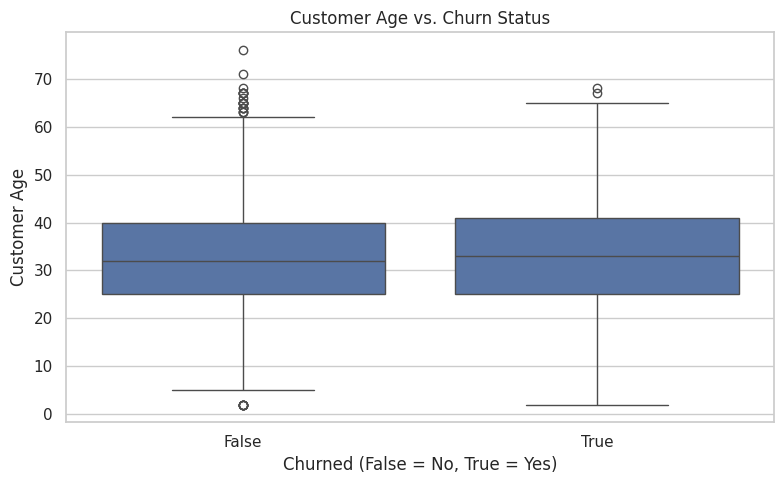

Average customer age by churn status:
churned
False    32.49
True     32.74
Name: age, dtype: float64


In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Combine customer information with churn labels
customer_churn = cleaned_datasets["customers"].merge(
    cleaned_datasets["churn_labels"],
    on="customer_id",
    how="inner"
)

# Compare age distribution across churn groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=customer_churn,
    x="churned",
    y="age"
)

plt.title("Customer Age vs. Churn Status")
plt.xlabel("Churned (False = No, True = Yes)")
plt.ylabel("Customer Age")
plt.tight_layout()
plt.show()

# Calculate average age for each churn group
print("Average customer age by churn status:")
print(
    customer_churn.groupby("churned")["age"].mean().round(2)
)

### 10.1 Customer Age vs. Churn Status – Interpretation

The analysis compares customer age across churned and non-churned customers.

**Key Observations:**

1. The average age of non-churned customers is 32.49 years.
2. The average age of churned customers is 32.74 years.
3. Both groups have very similar age distributions and median values.
4. The difference in average age is very small.

**Conclusion:**

Customer age alone does not appear to show a strong difference between churned and non-churned customers in this dataset. Therefore, age should be analysed along with other factors such as subscription plans, viewing behaviour, payment history and customer feedback.

Unusually low and high age values should also be considered carefully during interpretation.

Churn Rate by Subscription Plan:
         total_subscriptions  churned_subscriptions  churn_rate
plan_id                                                        
PLAN01                  3671                    977       26.61
PLAN02                  3301                    816       24.72
PLAN03                  1903                    437       22.96


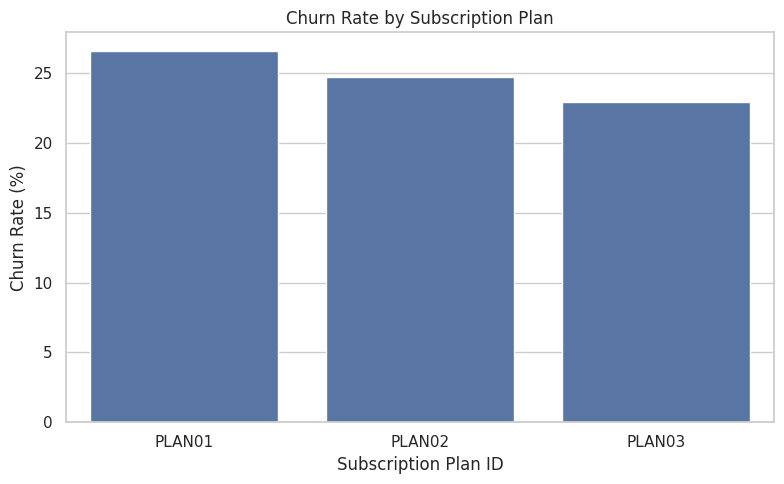

In [62]:
# Merge subscription information with churn labels

subscription_churn = cleaned_datasets["subscriptions"].merge(
    cleaned_datasets["churn_labels"][["customer_id", "churned"]],
    on="customer_id",
    how="inner"
)

# Calculate churn rate for each subscription plan
plan_churn = subscription_churn.groupby("plan_id").agg(
    total_subscriptions=("churned", "count"),
    churned_subscriptions=("churned", "sum")
)

plan_churn["churn_rate"] = (
    plan_churn["churned_subscriptions"] /
    plan_churn["total_subscriptions"] * 100
)

print("Churn Rate by Subscription Plan:")
print(plan_churn.round(2))

# Visualise churn rate
plt.figure(figsize=(8, 5))

sns.barplot(
    data=plan_churn.reset_index(),
    x="plan_id",
    y="churn_rate"
)

plt.title("Churn Rate by Subscription Plan")
plt.xlabel("Subscription Plan ID")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

### 10.2 Subscription Plan vs. Churn – Interpretation

This analysis examines the relationship between subscription plans and customer churn.

**Key Observations:**

1. PLAN01 has the highest observed churn rate of 26.61%.
2. PLAN02 has a churn rate of 24.72%.
3. PLAN03 has the lowest observed churn rate of 22.96%.
4. The difference between the highest and lowest churn rates is 3.65 percentage points.

**Conclusion:**

The results show some variation in churn rates across subscription plans. PLAN01 has a higher observed churn rate, while PLAN03 has a lower observed churn rate.

However, these results show an association and do not establish that the subscription plan causes customers to churn.

**Data Interpretation Note:** The calculation uses subscription records joined with customer-level churn labels. Customers with multiple subscription records may appear more than once. Therefore, these figures represent churn rates across subscription records, not unique customers assigned exclusively to their final subscription plan.

In [63]:
print(
    cleaned_datasets["subscription_plans"][
        ["plan_id", "plan_name", "monthly_price"]
    ]
)

  plan_id plan_name  monthly_price
0  PLAN01     Basic           6.99
1  PLAN02  Standard          15.49
2  PLAN03   Premium          22.99


### 10.2 Subscription Plan vs. Churn – Interpretation

This analysis examines the relationship between subscription plans and customer churn.

**Key Observations:**

1. The Basic plan ($6.99/month) has the highest observed churn rate of 26.61%.
2. The Standard plan ($15.49/month) has a churn rate of 24.72%.
3. The Premium plan ($22.99/month) has the lowest observed churn rate of 22.96%.
4. The difference between the Basic and Premium plan churn rates is 3.65 percentage points.

**Conclusion:**

The Basic plan shows a higher observed churn rate than the Standard and Premium plans. The Premium plan has the lowest observed churn rate.

This indicates a possible association between subscription plan and customer churn. However, it does not prove that subscription price or plan type causes churn.

**Data Interpretation Note:** The analysis uses subscription records joined with customer-level churn labels. Customers with multiple subscription records may appear more than once. Therefore, the results represent churn rates across subscription records rather than unique customers grouped exclusively by their final subscription plan.

Average Viewing Duration by Churn Status:
churned
False    49.49
True     49.26
Name: watch_duration_minutes, dtype: float64


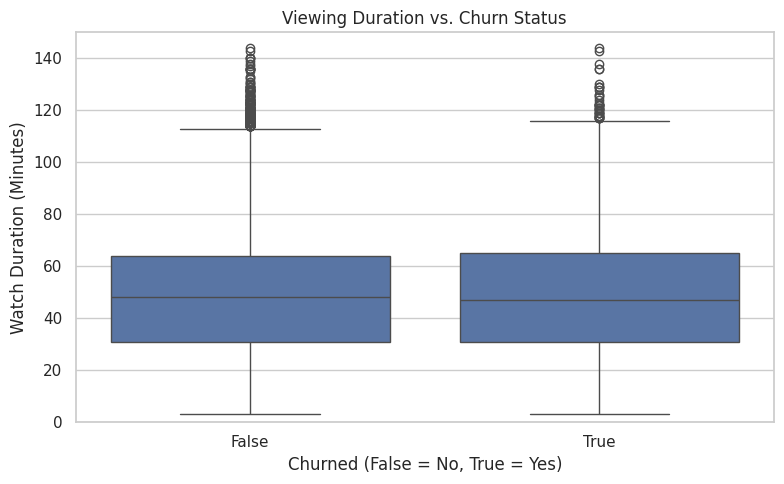

In [64]:
# Merge viewing activity with customer churn labels

viewing_churn = cleaned_datasets["viewing_activity"].merge(
    cleaned_datasets["churn_labels"][["customer_id", "churned"]],
    on="customer_id",
    how="inner"
)

# Calculate average viewing duration by churn status
print("Average Viewing Duration by Churn Status:")

print(
    viewing_churn.groupby("churned")[
        "watch_duration_minutes"
    ].mean().round(2)
)

# Visualize viewing duration by churn status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=viewing_churn,
    x="churned",
    y="watch_duration_minutes"
)

plt.ylim(0, 150)
plt.title("Viewing Duration vs. Churn Status")
plt.xlabel("Churned (False = No, True = Yes)")
plt.ylabel("Watch Duration (Minutes)")
plt.tight_layout()
plt.show()

### 10.3 Viewing Duration vs. Churn Status – Interpretation

This analysis examines whether viewing duration differs between churned and non-churned customers.

**Key Observations:**

1. The average viewing duration for non-churned customers is 49.49 minutes.
2. The average viewing duration for churned customers is 49.26 minutes.
3. Both groups show very similar viewing-duration distributions.
4. Both groups contain some unusually long viewing records.

**Conclusion:**

The average viewing duration is almost identical for churned and non-churned customers. This suggests that watch duration alone may not be sufficient to distinguish customers who churn from those who remain subscribed.

Further analysis of viewing frequency, recent activity and changes in viewing behaviour may provide additional insights.

**Data Interpretation Note:** The analysis compares viewing records joined with customer-level churn labels. Customers with more viewing sessions contribute more records. Therefore, these averages represent viewing sessions, not the average viewing duration per unique customer.

Payment Failure Rate by Churn Status:
         total_payments  failed_payments  failure_rate
churned                                               
False             83572             4949          5.92
True              27163             2257          8.31


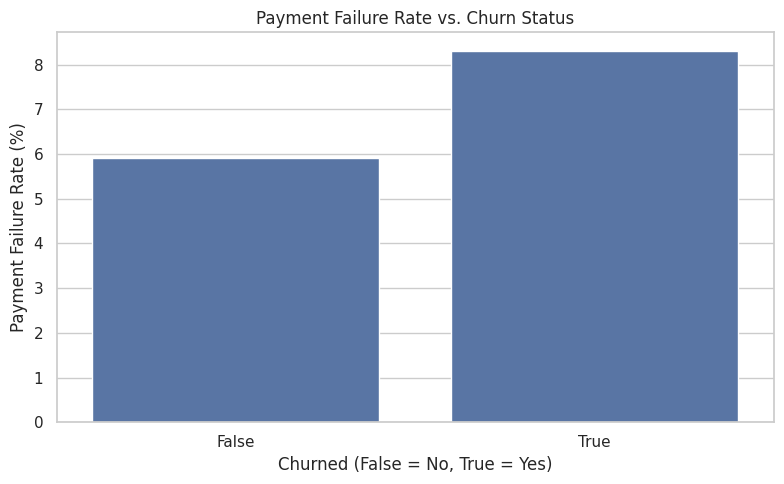

In [65]:
# Merge payment records with customer churn labels

payment_churn = cleaned_datasets["payments"].merge(
    cleaned_datasets["churn_labels"][["customer_id", "churned"]],
    on="customer_id",
    how="inner"
)

# Calculate payment failure rate by churn status

payment_summary = payment_churn.groupby("churned").agg(
    total_payments=("payment_id", "count"),
    failed_payments=("payment_status", lambda x: (x == "Failed").sum())
)

payment_summary["failure_rate"] = (
    payment_summary["failed_payments"] /
    payment_summary["total_payments"] * 100
)

print("Payment Failure Rate by Churn Status:")
print(payment_summary.round(2))

# Visualise payment failure rate

plt.figure(figsize=(8, 5))

sns.barplot(
    data=payment_summary.reset_index(),
    x="churned",
    y="failure_rate"
)

plt.title("Payment Failure Rate vs. Churn Status")
plt.xlabel("Churned (False = No, True = Yes)")
plt.ylabel("Payment Failure Rate (%)")
plt.tight_layout()
plt.show()

### 10.4 Payment Failure Rate vs. Churn Status – Interpretation

This analysis examines whether payment failures are associated with customer churn.

**Key Observations:**

1. Non-churned customers have 83,572 payment records, including 4,949 failed transactions.
2. Churned customers have 27,163 payment records, including 2,257 failed transactions.
3. The payment failure rate among non-churned customers is 5.92%.
4. The payment failure rate among churned customers is 8.31%.
5. Churned customers show a 2.39 percentage-point higher payment failure rate.

**Conclusion:**

Payment failures are more common among churned customers than non-churned customers. This suggests that payment-related issues may be associated with customer churn.

Monitoring failed transactions and improving payment recovery processes may help identify customers who need additional support.

**Data Interpretation Note:** The analysis is based on payment transactions joined with customer-level churn labels. Customers may have multiple payment records, so these percentages represent transaction-level failure rates rather than the percentage of unique customers experiencing payment failures. This analysis also shows association, not causation.

Average Feedback Rating by Churn Status:
churned
False    3.23
True     2.97
Name: rating, dtype: float64


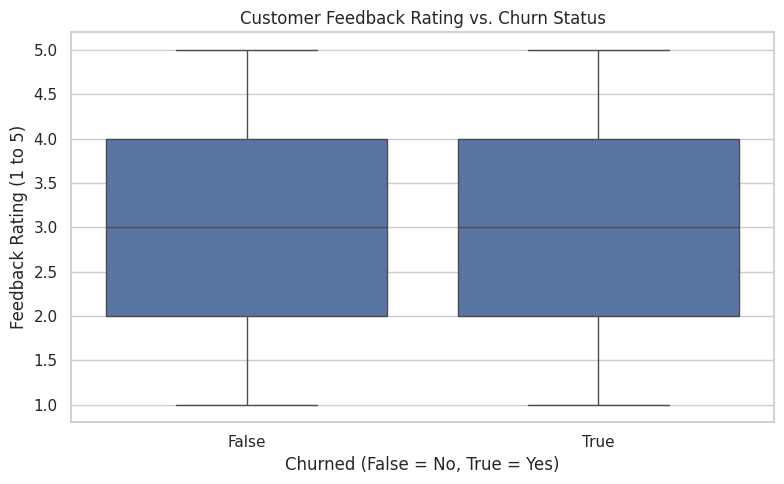

In [66]:
# Merge customer feedback with churn labels

feedback_churn = cleaned_datasets["customer_feedback"].merge(
    cleaned_datasets["churn_labels"][["customer_id", "churned"]],
    on="customer_id",
    how="inner"
)

# Calculate average feedback rating by churn status

print("Average Feedback Rating by Churn Status:")

print(
    feedback_churn.groupby("churned")["rating"]
    .mean()
    .round(2)
)

# Visualize feedback ratings by churn status

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=feedback_churn,
    x="churned",
    y="rating",
    order=[False, True]
)

plt.title("Customer Feedback Rating vs. Churn Status")
plt.xlabel("Churned (False = No, True = Yes)")
plt.ylabel("Feedback Rating (1 to 5)")
plt.tight_layout()
plt.show()

### 10.5 Customer Feedback Rating vs. Churn Status – Interpretation

This analysis examines the relationship between customer feedback ratings and customer churn.

**Key Observations:**

1. The average feedback rating of non-churned customers is 3.23.
2. The average feedback rating of churned customers is 2.97.
3. Both groups have a median feedback rating of 3.
4. Churned customers give slightly lower ratings on average, with a difference of 0.26 points.

**Conclusion:**

The results suggest that churned customers tend to provide slightly lower feedback ratings than non-churned customers. Customer satisfaction may therefore be a useful factor to investigate when understanding churn behaviour.

However, the difference is relatively small, and feedback ratings alone may not be sufficient to predict churn.

**Data Interpretation Note:** The analysis includes customers who submitted feedback. Some customers may have submitted multiple feedback records, so the results represent feedback records rather than unique customers. Customers without feedback are not represented in this comparison.

Support Ticket Summary by Churn Status:
         total_tickets  unique_customers
churned                                 
False             4474              3324
True              1646              1084

Average Support Tickets per Customer:
churned
False    1.35
True     1.52
Name: tickets_per_customer, dtype: float64


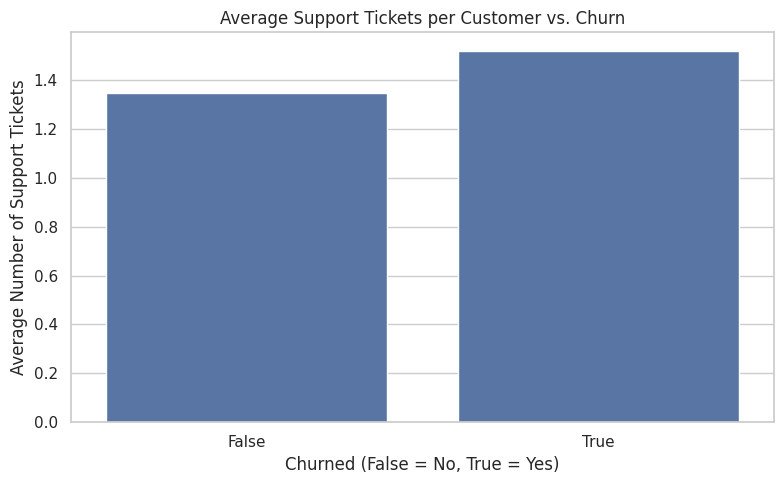

In [67]:
# Merge support tickets with customer churn labels

support_churn = cleaned_datasets["support_tickets"].merge(
    cleaned_datasets["churn_labels"][["customer_id", "churned"]],
    on="customer_id",
    how="inner"
)

# Count support tickets by churn status

support_summary = support_churn.groupby("churned").agg(
    total_tickets=("ticket_id", "count"),
    unique_customers=("customer_id", "nunique")
)

print("Support Ticket Summary by Churn Status:")
print(support_summary)

# Calculate average tickets per customer

support_summary["tickets_per_customer"] = (
    support_summary["total_tickets"] /
    support_summary["unique_customers"]
)

print("\nAverage Support Tickets per Customer:")
print(support_summary["tickets_per_customer"].round(2))

# Visualize total support tickets

plt.figure(figsize=(8, 5))

sns.barplot(
    data=support_summary.reset_index(),
    x="churned",
    y="tickets_per_customer"
)

plt.title("Average Support Tickets per Customer vs. Churn")
plt.xlabel("Churned (False = No, True = Yes)")
plt.ylabel("Average Number of Support Tickets")
plt.tight_layout()
plt.show()

### 10.6 Support Tickets vs. Churn Status – Interpretation

This analysis examines whether the number of customer support tickets is associated with customer churn.

**Key Observations:**

1. Non-churned customers generated 4,474 support tickets from 3,324 unique customers.
2. Churned customers generated 1,646 support tickets from 1,084 unique customers.
3. Non-churned customers raised an average of 1.35 support tickets per customer.
4. Churned customers raised an average of 1.52 support tickets per customer.
5. Churned customers generated approximately 0.17 more support tickets per customer.

**Conclusion:**

Churned customers have a slightly higher average number of support tickets than non-churned customers. This suggests that repeated customer support interactions may be associated with customer dissatisfaction or unresolved issues.

Monitoring support interactions and resolving recurring customer problems may help improve customer retention.

**Data Interpretation Note:** The analysis includes customers who raised at least one support ticket. Customers without support tickets are not included in the calculation. The results show an association and do not establish causation.

## 10.7 Overall Bivariate Analysis Findings

The bivariate analysis explored relationships between customer characteristics, subscription details, viewing behaviour, payment activity, feedback ratings, support interactions and customer churn.

**Major Findings:**

1. Customer age showed very little difference between churned and non-churned customers.
2. The Basic subscription plan had the highest observed churn rate among the three plans.
3. Average viewing duration was almost identical across both churn groups.
4. Churned customers had a higher payment failure rate than non-churned customers.
5. Churned customers provided slightly lower average feedback ratings.
6. Churned customers generated slightly more support tickets per customer.

**Overall Conclusion:**

Payment failures, customer feedback and support interactions showed potentially useful relationships with churn. Subscription plan also showed some variation in churn rates.

These findings provide useful directions for feature engineering and churn prediction. Further statistical analysis and machine learning will help evaluate the predictive value of these variables.

The comparisons are exploratory and show associations rather than causal relationships. Several analyses use transaction-, subscription- or feedback-level records, so their denominators differ.

## 11. Time-Based Analysis

Time-based analysis helps identify trends and patterns in customer activity over time.

In this section, we will examine customer registrations, subscription cancellations, payment transactions and viewing activity using date-based analysis.

The objective is to understand customer growth, cancellation patterns, payment trends and changes in viewing behaviour over time.

Monthly Customer Registrations:
   registration_month  new_customers
74            2025-03             87
75            2025-04             87
76            2025-05             81
77            2025-06             86
78            2025-07             91
79            2025-08             87
80            2025-09             88
81            2025-10            110
82            2025-11             81
83            2025-12             86
84            2026-01             84
85            2026-02            101
86            2026-03            103
87            2026-04             79
88            2026-05             83


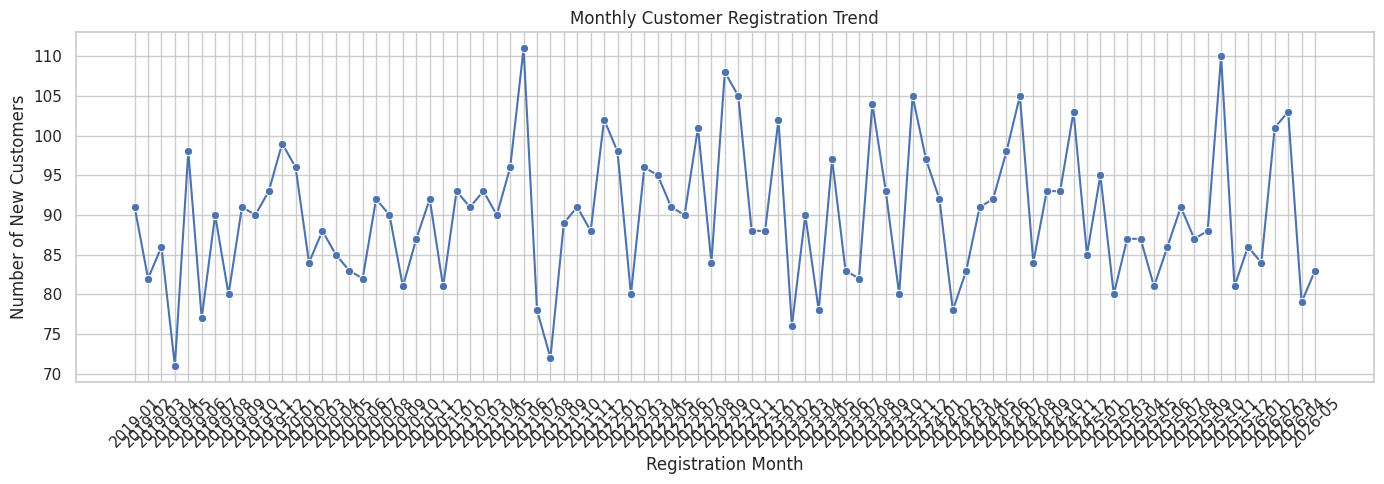

In [68]:
# Monthly Customer Registration Analysis

customers = cleaned_datasets["customers"].copy()

# Extract year and month from registration date
customers["registration_month"] = (
    customers["registration_date"].dt.to_period("M")
)

# Count registrations by month
monthly_registrations = (
    customers.groupby("registration_month")
    .size()
    .reset_index(name="new_customers")
)

print("Monthly Customer Registrations:")
print(monthly_registrations.tail(15))

# Visualize monthly registrations
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_registrations,
    x=monthly_registrations["registration_month"].astype(str),
    y="new_customers",
    marker="o"
)

plt.title("Monthly Customer Registration Trend")
plt.xlabel("Registration Month")
plt.ylabel("Number of New Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

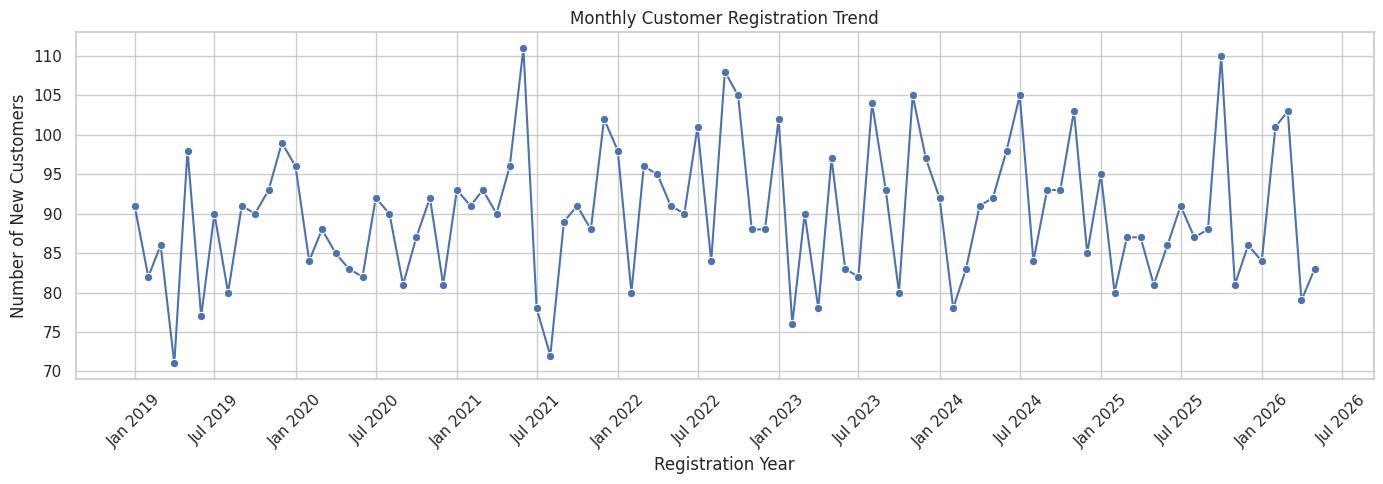

In [69]:
import matplotlib.dates as mdates

# Convert monthly periods into timestamps
monthly_registrations["month_date"] = (
    monthly_registrations["registration_month"].dt.to_timestamp()
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_registrations,
    x="month_date",
    y="new_customers",
    marker="o"
)

plt.title("Monthly Customer Registration Trend")
plt.xlabel("Registration Year")
plt.ylabel("Number of New Customers")

# Display one label every 6 months
plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.1 Monthly Customer Registration – Interpretation

This analysis examines the number of new customers registering each month from January 2019 to May 2026.

**Key Observations:**

1. Monthly customer registrations fluctuate over the observed period.
2. Most months show approximately 80–100 new customer registrations.
3. October 2025 recorded 110 new registrations in the displayed recent period.
4. February and March 2026 recorded 101 and 103 new registrations respectively.
5. April 2026 showed a decline to 79 registrations, followed by 83 registrations in May 2026.

**Conclusion:**

Customer registrations show month-to-month variation without an obvious consistent upward or downward trend in the displayed chart. Monitoring these patterns can help understand customer acquisition performance over time.

Monthly Subscription Cancellations:
  cancellation_month  cancelled_subscriptions
0            2025-10                      192
1            2025-11                      194
2            2025-12                      204
3            2026-01                      247
4            2026-02                      185
5            2026-03                      211
6            2026-04                      219
7            2026-05                      248
8            2026-06                      249


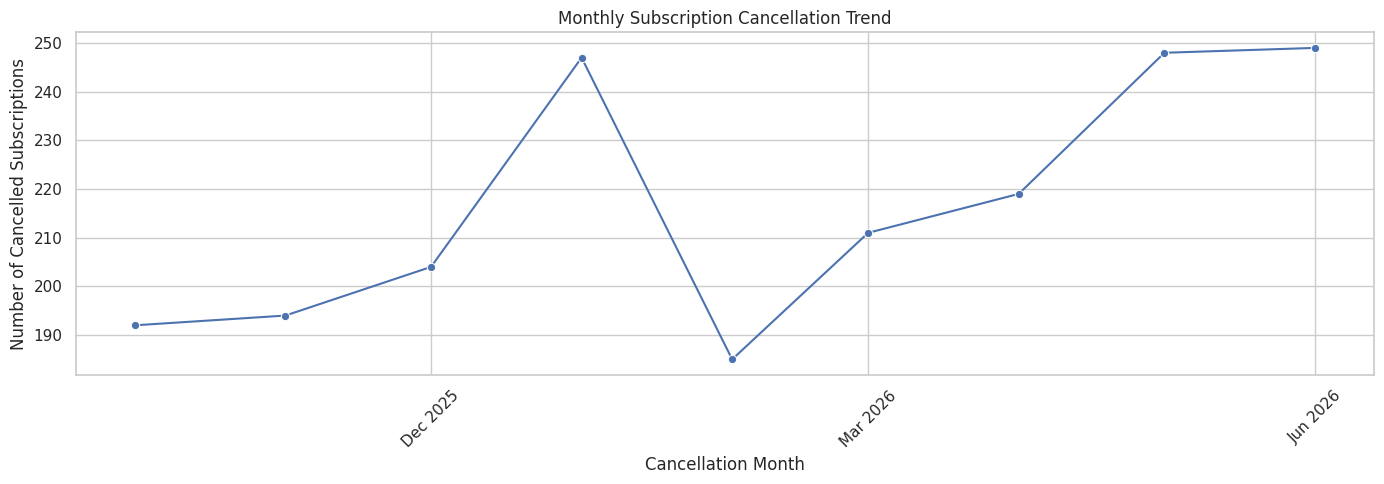

In [70]:
# Monthly Subscription Cancellation Analysis

subscriptions = cleaned_datasets["subscriptions"].copy()

# Select records with valid cancellation dates
cancelled_subscriptions = subscriptions[
    subscriptions["validated_cancellation_date"].notna()
].copy()

# Extract cancellation month
cancelled_subscriptions["cancellation_month"] = (
    cancelled_subscriptions["validated_cancellation_date"].dt.to_period("M")
)

# Count cancellations by month
monthly_cancellations = (
    cancelled_subscriptions.groupby("cancellation_month")
    .size()
    .reset_index(name="cancelled_subscriptions")
)

print("Monthly Subscription Cancellations:")
print(monthly_cancellations.tail(15))

# Visualize monthly cancellations
monthly_cancellations["month_date"] = (
    monthly_cancellations["cancellation_month"].dt.to_timestamp()
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_cancellations,
    x="month_date",
    y="cancelled_subscriptions",
    marker="o"
)

plt.title("Monthly Subscription Cancellation Trend")
plt.xlabel("Cancellation Month")
plt.ylabel("Number of Cancelled Subscriptions")

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.2 Monthly Subscription Cancellation – Interpretation

This analysis examines the number of subscription cancellations recorded each month using validated cancellation dates.

**Key Observations:**

1. October 2025 recorded 192 cancellations.
2. January 2026 recorded 247 cancellations.
3. February 2026 showed a decline to 185 cancellations.
4. Cancellations increased from March 2026 onwards.
5. June 2026 recorded the highest number of cancellations, with 249 records.

**Conclusion:**

Subscription cancellations fluctuate over the observed period. The increase towards May and June 2026 indicates that cancellation activity was relatively high during these months.

Monitoring monthly cancellation patterns can help identify periods requiring additional customer retention efforts.

**Data Interpretation Note:** This analysis uses validated cancellation dates. The 42 records with invalid cancellation-date relationships were excluded. The displayed period covers October 2025 to June 2026, so it should not be interpreted as a complete long-term cancellation trend.

Monthly Payment Summary:
   payment_month  total_transactions  successful_payments  failed_payments  \
74       2025-03                1379                 1280               99   
75       2025-04                1342                 1243               99   
76       2025-05                1382                 1293               89   
77       2025-06                1342                 1247               95   
78       2025-07                1391                 1306               85   
79       2025-08                1373                 1291               82   
80       2025-09                1328                 1248               80   
81       2025-10                1380                 1282               98   
82       2025-11                1328                 1254               74   
83       2025-12                1372                 1288               84   
84       2026-01                1355                 1264               91   
85       2026-02                1204   

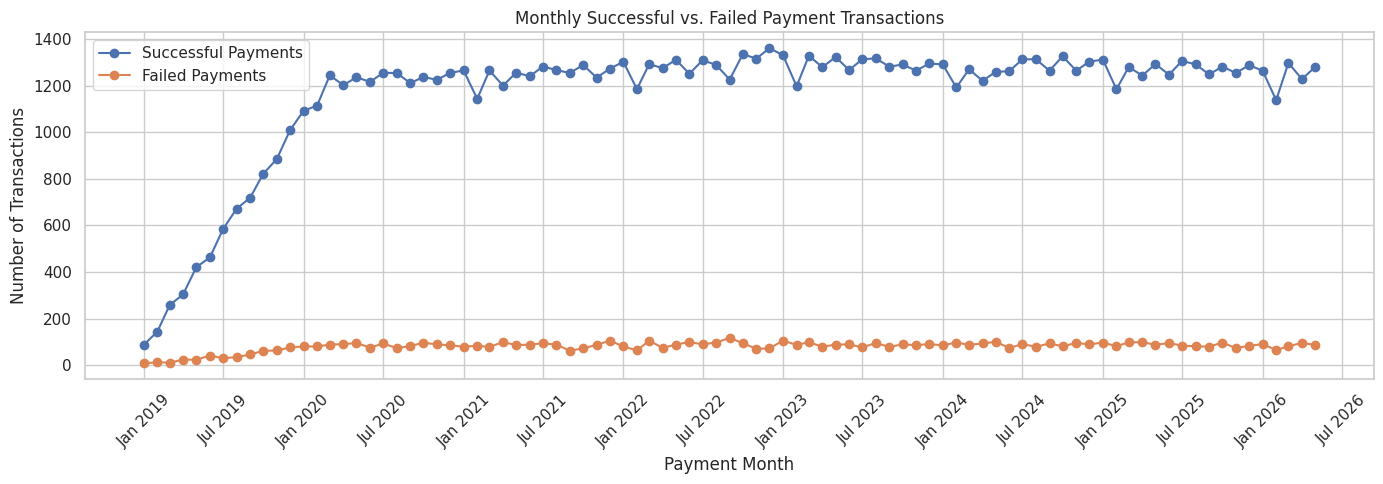

In [71]:
# Monthly Payment Transaction Analysis

payments = cleaned_datasets["payments"].copy()

# Extract payment month
payments["payment_month"] = (
    payments["payment_date"].dt.to_period("M")
)

# Calculate monthly payment transactions
monthly_payments = payments.groupby("payment_month").agg(
    total_transactions=("payment_id", "count"),
    successful_payments=("payment_status",
                         lambda x: (x == "Success").sum()),
    failed_payments=("payment_status",
                     lambda x: (x == "Failed").sum()),
    total_payment_amount=("amount", "sum")
).reset_index()

print("Monthly Payment Summary:")
print(monthly_payments.tail(15).round(2))

# Convert month to timestamp
monthly_payments["month_date"] = (
    monthly_payments["payment_month"].dt.to_timestamp()
)

# Visualize successful and failed transactions
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_payments["month_date"],
    monthly_payments["successful_payments"],
    marker="o",
    label="Successful Payments"
)

plt.plot(
    monthly_payments["month_date"],
    monthly_payments["failed_payments"],
    marker="o",
    label="Failed Payments"
)

plt.title("Monthly Successful vs. Failed Payment Transactions")
plt.xlabel("Payment Month")
plt.ylabel("Number of Transactions")
plt.legend()

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.3 Monthly Payment Trends – Interpretation

This analysis examines successful and failed payment transactions from January 2019 to May 2026.

**Key Observations:**

1. Successful payment transactions increased during the initial period from 2019 to early 2020.
2. After this growth, successful transactions generally remained between approximately 1,200 and 1,350 per month.
3. Failed payment transactions also increased during the initial period.
4. In the later period, failed transactions generally fluctuated around 70–110 per month.
5. Successful payments consistently exceeded failed payments throughout the displayed period.

**Conclusion:**

The business experienced growth in payment activity during its initial years, followed by relatively stable monthly transaction volumes.

Monitoring failed-payment trends is important because payment difficulties can affect subscription renewals and customer retention.

Monthly Payment Failure Rate:
   payment_month  total_transactions  failed_payments  payment_failure_rate
74       2025-03                1379               99                  7.18
75       2025-04                1342               99                  7.38
76       2025-05                1382               89                  6.44
77       2025-06                1342               95                  7.08
78       2025-07                1391               85                  6.11
79       2025-08                1373               82                  5.97
80       2025-09                1328               80                  6.02
81       2025-10                1380               98                  7.10
82       2025-11                1328               74                  5.57
83       2025-12                1372               84                  6.12
84       2026-01                1355               91                  6.72
85       2026-02                1204               66     

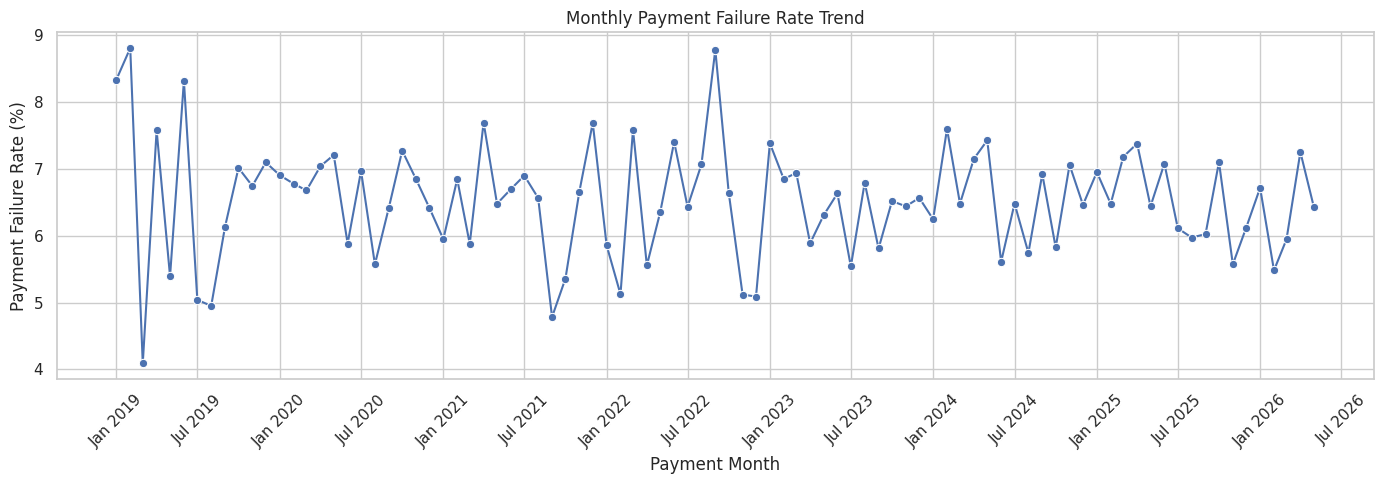

In [72]:
# Calculate Monthly Payment Failure Rate

monthly_payments["payment_failure_rate"] = (
    monthly_payments["failed_payments"]
    / monthly_payments["total_transactions"]
) * 100

print("Monthly Payment Failure Rate:")
print(
    monthly_payments[
        ["payment_month", "total_transactions",
         "failed_payments", "payment_failure_rate"]
    ].tail(15).round(2)
)

# Visualize payment failure rate
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_payments,
    x="month_date",
    y="payment_failure_rate",
    marker="o"
)

plt.title("Monthly Payment Failure Rate Trend")
plt.xlabel("Payment Month")
plt.ylabel("Payment Failure Rate (%)")

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.4 Monthly Payment Failure Rate – Interpretation

This analysis calculates the monthly percentage of failed payment transactions relative to all payment transactions.

**Key Observations:**

1. Monthly payment failure rates fluctuate over time.
2. April 2025 recorded a failure rate of 7.38% in the displayed recent period.
3. February 2026 recorded the lowest failure rate in this period at 5.48%.
4. April 2026 showed an increase to 7.25%, followed by a decrease to 6.43% in May.
5. Recent monthly failure rates generally remained between approximately 5.5% and 7.4%.

**Conclusion:**

Payment failures remain an important area to monitor. Monthly failure-rate analysis provides a fairer comparison across months with different transaction volumes.

These findings can help identify payment-related issues that may affect subscription renewals and customer retention.

Churn Rate by Subscription Plan:
  plan_id  total_subscriptions  churned_subscriptions  churn_rate plan_name
0  PLAN01                 3671                    977       26.61     Basic
1  PLAN02                 3301                    816       24.72  Standard
2  PLAN03                 1903                    437       22.96   Premium


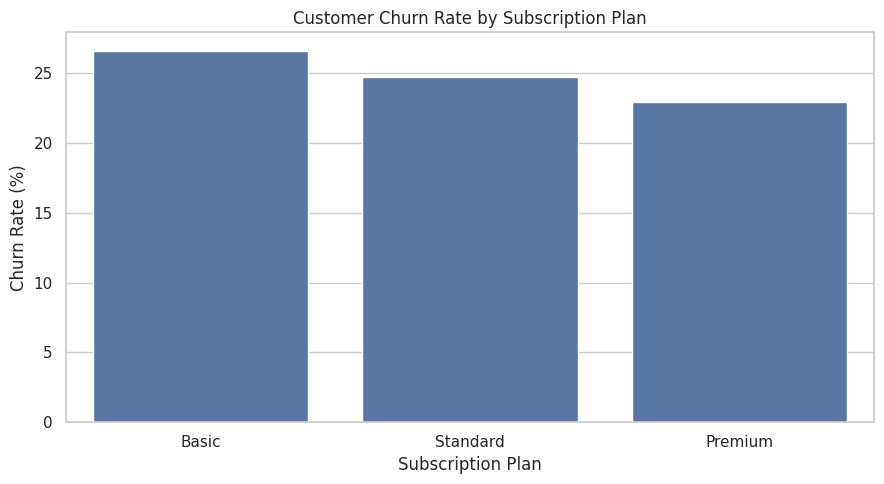

In [73]:
# Customer Churn Rate by Subscription Plan

subscriptions = cleaned_datasets["subscriptions"].copy()
churn_labels = cleaned_datasets["churn_labels"].copy()
plans = cleaned_datasets["subscription_plans"].copy()

# Merge subscription information with churn labels
plan_churn = subscriptions.merge(
    churn_labels[["customer_id", "churned"]],
    on="customer_id",
    how="left"
)

# Calculate churn rate for each plan
plan_churn_summary = plan_churn.groupby("plan_id").agg(
    total_subscriptions=("customer_id", "count"),
    churned_subscriptions=("churned", "sum")
).reset_index()

plan_churn_summary["churn_rate"] = (
    plan_churn_summary["churned_subscriptions"]
    / plan_churn_summary["total_subscriptions"]
) * 100

# Add plan names
plan_churn_summary = plan_churn_summary.merge(
    plans[["plan_id", "plan_name"]],
    on="plan_id",
    how="left"
)

print("Churn Rate by Subscription Plan:")
print(plan_churn_summary.round(2))

# Visualize churn rate
plt.figure(figsize=(9, 5))

sns.barplot(
    data=plan_churn_summary,
    x="plan_name",
    y="churn_rate",
    order=["Basic", "Standard", "Premium"]
)

plt.title("Customer Churn Rate by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [74]:
# Check how many unique customers are associated with each plan

customer_plan_summary = (
    subscriptions.groupby("plan_id")
    .agg(
        unique_customers=("customer_id", "nunique"),
        subscription_records=("subscription_id", "count")
    )
    .reset_index()
)

customer_plan_summary = customer_plan_summary.merge(
    plans[["plan_id", "plan_name"]],
    on="plan_id",
    how="left"
)

print("Unique Customers vs Subscription Records by Plan:")
print(customer_plan_summary)

Unique Customers vs Subscription Records by Plan:
  plan_id  unique_customers  subscription_records plan_name
0  PLAN01              3543                  3671     Basic
1  PLAN02              3193                  3301  Standard
2  PLAN03              1834                  1903   Premium


In [75]:
# Check customers associated with multiple subscription plans

customer_plan_counts = (
    subscriptions.groupby("customer_id")["plan_id"]
    .nunique()
)

print("Customers associated with multiple plans:",
      (customer_plan_counts > 1).sum())

print("\nDistribution of plans per customer:")
print(customer_plan_counts.value_counts().sort_index())

# Display a few examples
multiple_plan_customers = customer_plan_counts[
    customer_plan_counts > 1
].index

print("\nSample customers with multiple plans:")

print(
    subscriptions[
        subscriptions["customer_id"].isin(multiple_plan_customers)
    ][
        ["customer_id", "plan_id", "subscription_start_date",
         "subscription_status"]
    ].sort_values(["customer_id", "subscription_start_date"]).head(15)
)

Customers associated with multiple plans: 570

Distribution of plans per customer:
plan_id
1    7430
2     570
Name: count, dtype: int64

Sample customers with multiple plans:
    customer_id plan_id subscription_start_date subscription_status
35   CUST000035  PLAN03              2023-09-30        Plan Changed
36   CUST000035  PLAN01              2026-06-24              Active
48   CUST000047  PLAN03              2021-04-19        Plan Changed
49   CUST000047  PLAN01              2022-06-11              Active
59   CUST000055  PLAN02              2019-10-11        Plan Changed
60   CUST000055  PLAN01              2022-05-14           Cancelled
69   CUST000064  PLAN02              2020-06-30        Plan Changed
70   CUST000064  PLAN01              2026-05-23              Active
78   CUST000072  PLAN02              2020-02-20        Plan Changed
79   CUST000072  PLAN01              2025-08-18              Active
92   CUST000085  PLAN01              2022-01-05        Plan Changed
93   CUS

Customer-Level Churn Rate by Latest Subscription Plan:
  plan_id  total_customers  churned_customers  churn_rate plan_name
0  PLAN01             3368                886       26.31     Basic
1  PLAN02             3018                742       24.59  Standard
2  PLAN03             1614                363       22.49   Premium


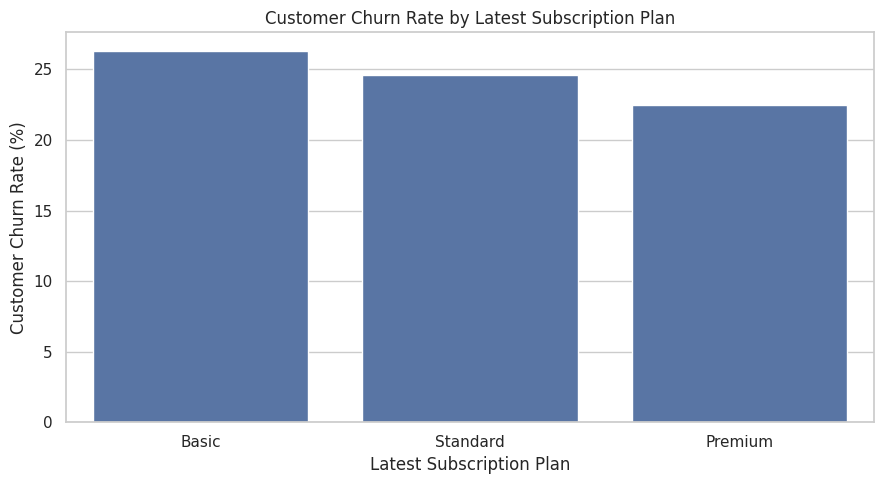

In [76]:
# Customer-Level Churn Rate by Latest Subscription Plan

# Sort subscriptions by customer and subscription start date
latest_subscriptions = subscriptions.sort_values(
    ["customer_id", "subscription_start_date"]
)

# Keep only the latest subscription for each customer
latest_subscriptions = (
    latest_subscriptions
    .drop_duplicates(subset="customer_id", keep="last")
)

# Attach customer churn labels
customer_plan_churn = latest_subscriptions.merge(
    churn_labels[["customer_id", "churned"]],
    on="customer_id",
    how="left"
)

# Calculate customer-level churn rate by latest plan
customer_plan_summary = customer_plan_churn.groupby("plan_id").agg(
    total_customers=("customer_id", "nunique"),
    churned_customers=("churned", "sum")
).reset_index()

customer_plan_summary["churn_rate"] = (
    customer_plan_summary["churned_customers"]
    / customer_plan_summary["total_customers"]
) * 100

# Add readable plan names
customer_plan_summary = customer_plan_summary.merge(
    plans[["plan_id", "plan_name"]],
    on="plan_id",
    how="left"
)

print("Customer-Level Churn Rate by Latest Subscription Plan:")
print(customer_plan_summary.round(2))

# Visualize results
plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_plan_summary,
    x="plan_name",
    y="churn_rate",
    order=["Basic", "Standard", "Premium"]
)

plt.title("Customer Churn Rate by Latest Subscription Plan")
plt.xlabel("Latest Subscription Plan")
plt.ylabel("Customer Churn Rate (%)")
plt.tight_layout()
plt.show()

### 11.5 Customer Churn Rate by Latest Subscription Plan – Interpretation

This analysis examines customer churn rates based on each customer's latest recorded subscription plan. Each customer is counted only once to avoid duplication caused by subscription changes.

**Key Observations:**

1. The Basic plan has 3,368 customers, of whom 886 churned, resulting in a churn rate of 26.31%.
2. The Standard plan has 3,018 customers, of whom 742 churned, resulting in a churn rate of 24.59%.
3. The Premium plan has 1,614 customers, of whom 363 churned, resulting in a churn rate of 22.49%.
4. The Basic plan has the highest observed churn rate, while the Premium plan has the lowest.
5. The difference between the Basic and Premium plan churn rates is 3.82 percentage points.

**Conclusion:**

Customers whose latest recorded subscription is the Basic plan show a higher observed churn rate than customers on the Standard and Premium plans.

This suggests a possible association between subscription plan and customer churn. However, the analysis does not establish that plan type or price causes churn.

**Data Interpretation Note:** Each customer is assigned to their latest subscription based on subscription start date. Churn status is taken from the customer-level churn labels. This is a descriptive comparison based on the latest recorded plan, not necessarily the plan held at the exact moment of cancellation.

Monthly Viewing Activity:
   viewing_month  total_viewing_sessions  total_watch_minutes  \
0        2025-07                    4829               236666   
1        2025-08                    4778               237115   
2        2025-09                    4697               232901   
3        2025-10                    5144               249998   
4        2025-11                    4994               246332   
5        2025-12                    5141               251427   
6        2026-01                    5321               262021   
7        2026-02                    5061               252908   
8        2026-03                    4384               214581   
9        2026-04                    4419               216495   
10       2026-05                    8804               441974   
11       2026-06                    8850               441078   

    average_watch_duration  
0                    49.01  
1                    49.63  
2                    49.59  
3           

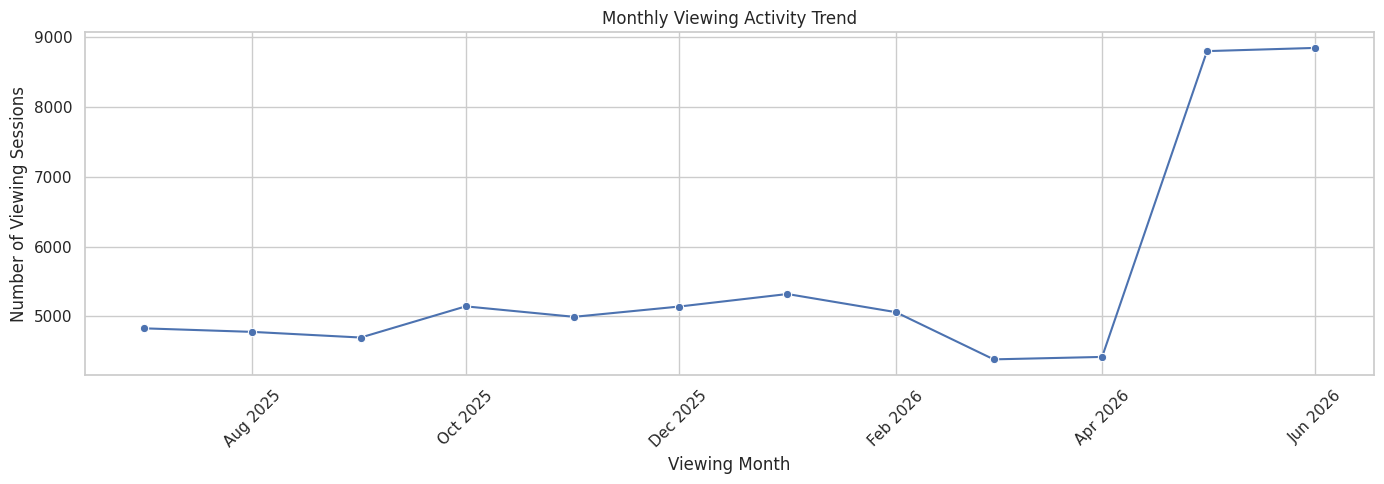

In [77]:
# Monthly Viewing Activity Analysis

viewing = cleaned_datasets["viewing_activity"].copy()

# Extract viewing month
viewing["viewing_month"] = (
    viewing["viewing_date"].dt.to_period("M")
)

# Calculate monthly viewing metrics
monthly_viewing = viewing.groupby("viewing_month").agg(
    total_viewing_sessions=("viewing_id", "count"),
    total_watch_minutes=("watch_duration_minutes", "sum"),
    average_watch_duration=("watch_duration_minutes", "mean")
).reset_index()

print("Monthly Viewing Activity:")
print(monthly_viewing.tail(15).round(2))

# Convert period to timestamp
monthly_viewing["month_date"] = (
    monthly_viewing["viewing_month"].dt.to_timestamp()
)

# Visualize monthly viewing sessions
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_viewing,
    x="month_date",
    y="total_viewing_sessions",
    marker="o"
)

plt.title("Monthly Viewing Activity Trend")
plt.xlabel("Viewing Month")
plt.ylabel("Number of Viewing Sessions")

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.6 Monthly Viewing Activity – Interpretation

This analysis examines monthly viewing sessions, total watch time and average viewing duration from July 2025 to June 2026.

**Key Observations:**

1. Monthly viewing sessions generally remained between approximately 4,700 and 5,300 from July 2025 to February 2026.
2. Viewing activity declined during March and April 2026.
3. May 2026 recorded a significant increase to 8,804 viewing sessions.
4. June 2026 recorded the highest activity, with 8,850 viewing sessions.
5. Average viewing duration remained relatively stable throughout the observed period, ranging from 48.60 to 50.20 minutes.

**Conclusion:**

Viewing activity fluctuated over the 12-month period. The sharp increase in May and June 2026 requires further investigation. Average viewing duration remained relatively consistent despite changes in the number of sessions.

**Data Interpretation Note:** These metrics represent viewing records, not unique customers. The increase in May and June should not automatically be interpreted as an increase in the customer base.

In [78]:
# Check unique customers and viewing sessions by month

monthly_viewing_customers = viewing.groupby(
    "viewing_month"
).agg(
    unique_customers=("customer_id", "nunique"),
    total_sessions=("viewing_id", "count"),
    sessions_per_customer=("viewing_id", "count")
).reset_index()

monthly_viewing_customers["sessions_per_customer"] = (
    monthly_viewing_customers["total_sessions"] /
    monthly_viewing_customers["unique_customers"]
)

print("Monthly Unique Customer and Viewing Activity:")
print(monthly_viewing_customers.round(2))

Monthly Unique Customer and Viewing Activity:
   viewing_month  unique_customers  total_sessions  sessions_per_customer
0        2025-07              3359            4829                   1.44
1        2025-08              3330            4778                   1.43
2        2025-09              3291            4697                   1.43
3        2025-10              3542            5144                   1.45
4        2025-11              3495            4994                   1.43
5        2025-12              3523            5141                   1.46
6        2026-01              3672            5321                   1.45
7        2026-02              3513            5061                   1.44
8        2026-03              3210            4384                   1.37
9        2026-04              3191            4419                   1.38
10       2026-05              4302            8804                   2.05
11       2026-06              4235            8850                

### 11.7 Monthly Viewing Activity – Customer-Level Investigation

To investigate the increase in viewing activity during May and June 2026, monthly unique customers and viewing sessions per customer were examined.

**Key Observations:**

1. April 2026 recorded 3,191 unique viewing customers and 4,419 sessions.
2. May 2026 recorded 4,302 unique viewing customers and 8,804 sessions.
3. Average sessions per customer increased from 1.38 in April to 2.05 in May.
4. June 2026 recorded 4,235 unique viewing customers and 8,850 sessions.
5. Average sessions per customer reached 2.09 in June.

**Conclusion:**

The increase in viewing activity during May and June 2026 is associated with both a higher number of unique active viewers and more viewing sessions per customer.

The reason for this increase cannot be established from these metrics alone. Further investigation may be required to understand whether the pattern reflects changes in customer behaviour or data-generation characteristics.

In [79]:
# Check daily viewing activity in each month

viewing["viewing_day"] = viewing["viewing_date"].dt.date

daily_viewing = viewing.groupby(
    "viewing_month"
).agg(
    first_viewing_date=("viewing_date", "min"),
    last_viewing_date=("viewing_date", "max"),
    active_viewing_days=("viewing_day", "nunique"),
    total_sessions=("viewing_id", "count")
).reset_index()

print("Monthly Viewing Data Coverage:")
print(daily_viewing)

Monthly Viewing Data Coverage:
   viewing_month first_viewing_date last_viewing_date  active_viewing_days  \
0        2025-07         2025-07-01        2025-07-31                   31   
1        2025-08         2025-08-01        2025-08-31                   31   
2        2025-09         2025-09-01        2025-09-30                   30   
3        2025-10         2025-10-01        2025-10-31                   31   
4        2025-11         2025-11-01        2025-11-30                   30   
5        2025-12         2025-12-01        2025-12-31                   31   
6        2026-01         2026-01-01        2026-01-31                   31   
7        2026-02         2026-02-01        2026-02-28                   28   
8        2026-03         2026-03-01        2026-03-31                   31   
9        2026-04         2026-04-01        2026-04-30                   30   
10       2026-05         2026-05-01        2026-05-31                   31   
11       2026-06         2026-06-

### 11.8 Monthly Viewing Data Coverage – Validation

A data coverage check was performed to investigate the sharp increase in viewing activity during May and June 2026.

**Key Observations:**

1. All 12 months have viewing records covering the complete calendar month.
2. May 2026 contains records from May 1 to May 31, with 31 active viewing days.
3. June 2026 contains records from June 1 to June 30, with 30 active viewing days.
4. The increase in viewing sessions during May and June is therefore not explained by incomplete monthly date coverage.

**Conclusion:**

The increase in viewing activity during May and June 2026 is a genuine pattern within the available dataset. Both unique active viewers and average viewing sessions per customer increased. Further investigation would be needed to identify the underlying reason.

**Note:** Complete date coverage does not independently establish that the dataset contains every real-world viewing event.

Monthly Watch Duration Analysis:
   viewing_month  average_watch_duration  median_watch_duration  \
0        2025-07                   49.01                   48.0   
1        2025-08                   49.63                   48.0   
2        2025-09                   49.59                   47.0   
3        2025-10                   48.60                   47.0   
4        2025-11                   49.33                   47.0   
5        2025-12                   48.91                   47.0   
6        2026-01                   49.24                   48.0   
7        2026-02                   49.97                   47.0   
8        2026-03                   48.95                   48.0   
9        2026-04                   48.99                   48.0   
10       2026-05                   50.20                   48.0   
11       2026-06                   49.84                   48.0   

    total_watch_minutes  
0                236666  
1                237115  
2                

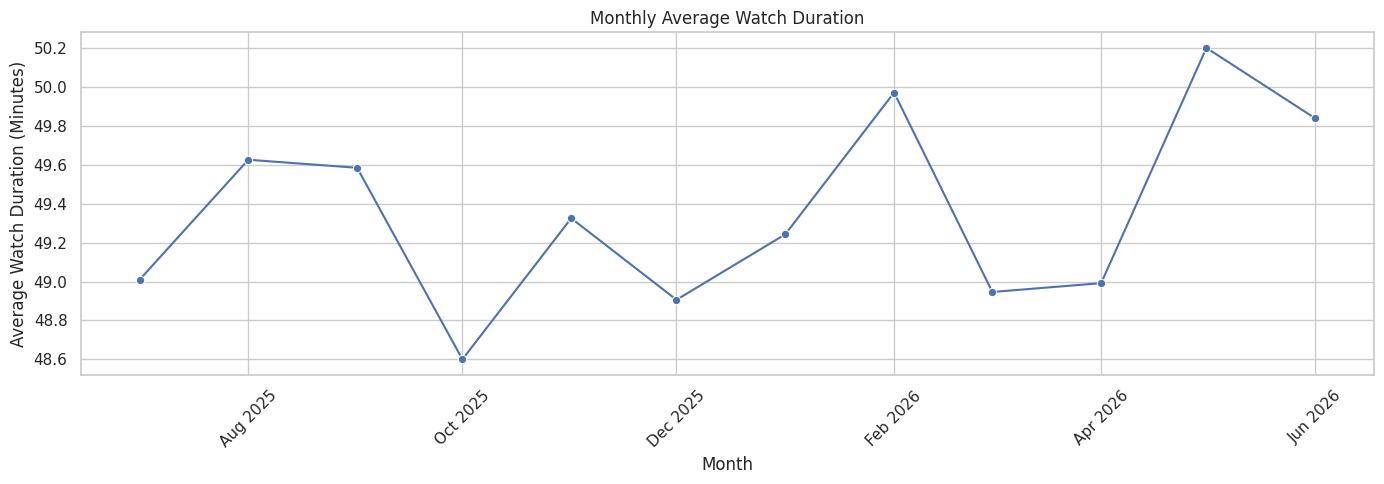

In [80]:
# Monthly Average Watch Duration Analysis

monthly_watch_duration = viewing.groupby(
    "viewing_month"
).agg(
    average_watch_duration=("watch_duration_minutes", "mean"),
    median_watch_duration=("watch_duration_minutes", "median"),
    total_watch_minutes=("watch_duration_minutes", "sum")
).reset_index()

print("Monthly Watch Duration Analysis:")
print(monthly_watch_duration.round(2))

# Convert period to timestamp
monthly_watch_duration["month_date"] = (
    monthly_watch_duration["viewing_month"].dt.to_timestamp()
)

# Visualize average watch duration
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_watch_duration,
    x="month_date",
    y="average_watch_duration",
    marker="o"
)

plt.title("Monthly Average Watch Duration")
plt.xlabel("Month")
plt.ylabel("Average Watch Duration (Minutes)")

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.9 Monthly Average Watch Duration – Interpretation

This analysis examines monthly average and median watch duration to understand changes in customer viewing behaviour.

**Key Observations:**

1. Average watch duration remained relatively stable throughout the 12-month period, ranging from 48.60 to 50.20 minutes.
2. May 2026 recorded the highest average watch duration of 50.20 minutes.
3. October 2025 recorded the lowest average watch duration of 48.60 minutes.
4. Median watch duration remained between 47 and 48 minutes across all months.
5. Total watch time increased considerably during May and June 2026, corresponding with the increase in viewing sessions.

**Conclusion:**

Although viewing activity increased significantly during May and June 2026, average watch duration remained stable. This suggests that the increase in total watch time was primarily associated with more viewing sessions rather than a substantial increase in time spent per session.

**Note:** These measurements are based on viewing sessions, not unique customers.

Monthly Support Ticket Analysis:
   ticket_month  total_tickets  resolved_tickets  average_resolution_hours
73      2025-04            132                97                     17.36
74      2025-05            131                92                     16.30
75      2025-06            147               108                     18.21
76      2025-07            147               122                     16.84
77      2025-08            152               116                     15.85
78      2025-09            150               117                     18.75
79      2025-10            150               115                     16.89
80      2025-11            166               126                     16.57
81      2025-12            178               135                     18.21
82      2026-01            192               141                     19.79
83      2026-02            175               145                     21.27
84      2026-03            219               165                   

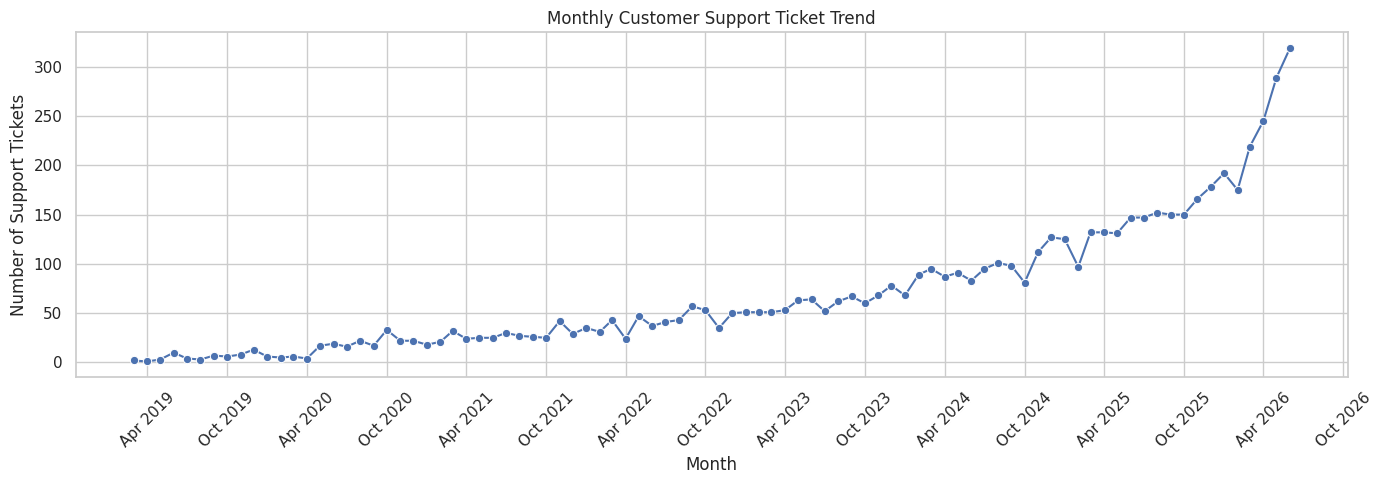

In [81]:
# Monthly Support Ticket Trend

tickets = cleaned_datasets["support_tickets"].copy()

# Extract ticket month
tickets["ticket_month"] = tickets["ticket_date"].dt.to_period("M")

# Calculate monthly support metrics
monthly_tickets = tickets.groupby("ticket_month").agg(
    total_tickets=("ticket_id", "count"),
    resolved_tickets=("ticket_status", lambda x: x.isin(["Resolved", "Closed"]).sum()),
    average_resolution_hours=("resolution_time_hours", "mean")
).reset_index()

print("Monthly Support Ticket Analysis:")
print(monthly_tickets.tail(15).round(2))

# Convert period to timestamp
monthly_tickets["month_date"] = (
    monthly_tickets["ticket_month"].dt.to_timestamp()
)

# Plot monthly ticket volume
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_tickets,
    x="month_date",
    y="total_tickets",
    marker="o"
)

plt.title("Monthly Customer Support Ticket Trend")
plt.xlabel("Month")
plt.ylabel("Number of Support Tickets")

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.10 Monthly Customer Support Ticket Trend – Interpretation

This analysis examines monthly customer support ticket volume, resolved or closed tickets, and average resolution time.

**Key Observations:**

1. April 2025 recorded 132 support tickets.
2. Support ticket volume generally increased over the observed period.
3. March 2026 recorded 219 tickets, increasing to 245 in April, 289 in May, and 319 in June.
4. June 2026 recorded the highest ticket volume.
5. Average resolution time fluctuated during the period, ranging from 15.85 to 21.27 hours in the displayed 15-month period.
6. In June 2026, 240 out of 319 tickets were marked Resolved or Closed.

**Conclusion:**

Customer support demand increased considerably, particularly during the final months of the analysis period. However, average resolution time did not show a consistent upward trend alongside ticket volume.

This finding highlights the importance of monitoring support demand, ticket resolution, and service efficiency.

**Note:** Average resolution time is calculated using records with available resolution-time values. Resolved and closed tickets are counted together in this analysis.

Monthly Customer Feedback Analysis:
   feedback_month_period  total_feedback  average_rating  negative_feedback  \
73               2025-04             100            3.17                 26   
74               2025-05              93            3.09                 30   
75               2025-06             112            3.24                 29   
76               2025-07             117            3.17                 30   
77               2025-08             110            3.32                 21   
78               2025-09             125            3.05                 42   
79               2025-10             133            3.28                 32   
80               2025-11             165            3.26                 47   
81               2025-12             164            3.18                 41   
82               2026-01             177            3.24                 49   
83               2026-02             143            3.22                 38   
84              

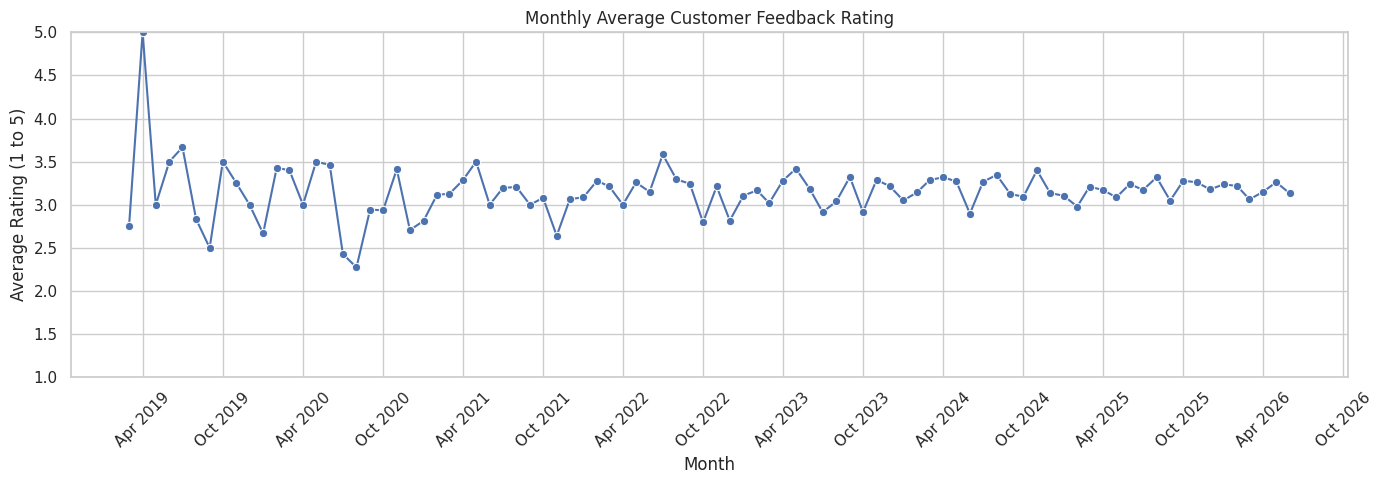

In [82]:
# Monthly Customer Feedback Analysis

feedback = cleaned_datasets["customer_feedback"].copy()

# Extract feedback month
feedback["feedback_month_period"] = (
    feedback["feedback_date"].dt.to_period("M")
)

# Calculate monthly feedback metrics
monthly_feedback = feedback.groupby(
    "feedback_month_period"
).agg(
    total_feedback=("feedback_id", "count"),
    average_rating=("rating", "mean"),
    negative_feedback=("sentiment_label", lambda x: (x == "Negative").sum()),
    positive_feedback=("sentiment_label", lambda x: (x == "Positive").sum())
).reset_index()

print("Monthly Customer Feedback Analysis:")
print(monthly_feedback.tail(15).round(2))

# Convert period to timestamp
monthly_feedback["month_date"] = (
    monthly_feedback["feedback_month_period"].dt.to_timestamp()
)

# Plot monthly average rating
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_feedback,
    x="month_date",
    y="average_rating",
    marker="o"
)

plt.title("Monthly Average Customer Feedback Rating")
plt.xlabel("Month")
plt.ylabel("Average Rating (1 to 5)")
plt.ylim(1, 5)

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.11 Monthly Customer Feedback Trend – Interpretation

This analysis examines monthly feedback volume, average customer ratings, and positive and negative feedback counts.

**Key Observations:**

1. Monthly feedback volume increased from 100 records in April 2025 to 245 records in June 2026.
2. Average customer ratings fluctuated between 3.05 and 3.32 during the displayed period.
3. August 2025 recorded the highest average rating of 3.32.
4. September 2025 recorded the lowest average rating of 3.05.
5. June 2026 recorded 94 positive and 72 negative feedback records.
6. Feedback volume increased considerably during the final months, while average ratings remained relatively stable.

**Conclusion:**

The increase in feedback volume indicates greater feedback activity in the later months of the observed period. However, average ratings did not show a consistent improvement or decline.

Monitoring both feedback volume and customer ratings can help identify changes in customer experience.

**Note:** These results represent feedback records, not necessarily unique customers. Positive and negative feedback counts are based on the sentiment labels in the dataset.

Monthly Customer Churn:
  churn_month  churned_customers
0     2025-10                198
1     2025-11                200
2     2025-12                213
3     2026-01                253
4     2026-02                190
5     2026-03                213
6     2026-04                223
7     2026-05                250
8     2026-06                251


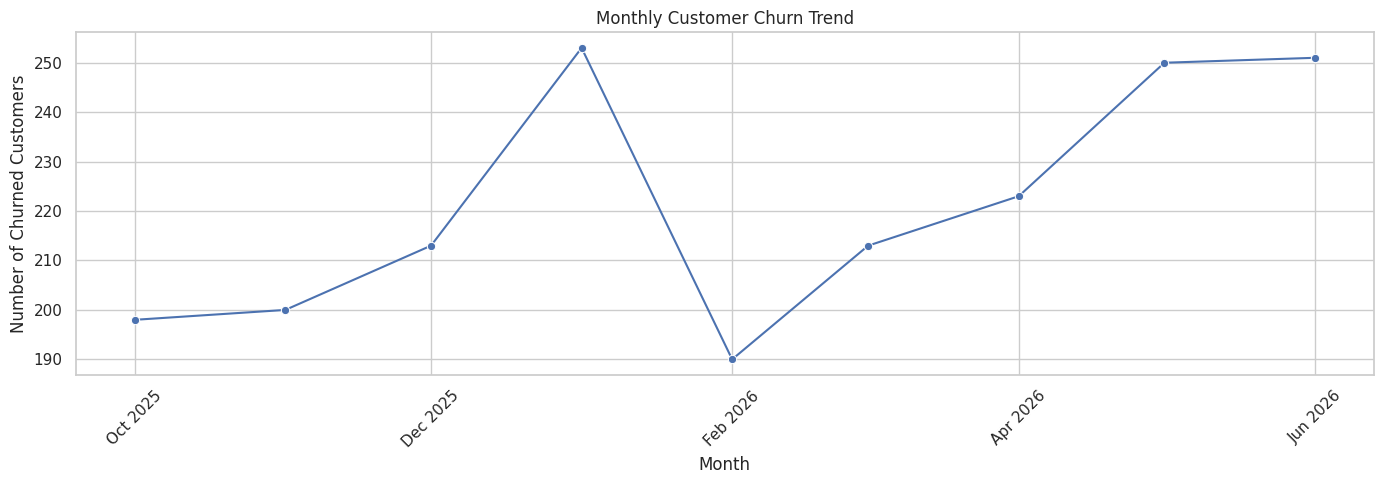

In [83]:
# Monthly Customer Churn Analysis

churn = cleaned_datasets["churn_labels"].copy()

# Use only valid churn dates
churned_customers = churn[
    (churn["churned"] == True) &
    (churn["churn_date"].notna())
].copy()

# Extract churn month
churned_customers["churn_month"] = (
    churned_customers["churn_date"].dt.to_period("M")
)

# Calculate monthly churn counts
monthly_churn = churned_customers.groupby(
    "churn_month"
).agg(
    churned_customers=("customer_id", "nunique")
).reset_index()

print("Monthly Customer Churn:")
print(monthly_churn)

# Convert period to timestamp
monthly_churn["month_date"] = (
    monthly_churn["churn_month"].dt.to_timestamp()
)

# Visualize monthly churn
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_churn,
    x="month_date",
    y="churned_customers",
    marker="o"
)

plt.title("Monthly Customer Churn Trend")
plt.xlabel("Month")
plt.ylabel("Number of Churned Customers")

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 11.12 Monthly Customer Churn Trend – Interpretation

This analysis examines the number of customers who churned each month using valid churn dates.

**Key Observations:**

1. Monthly churn records ranged from 190 to 253 customers during the observed period.
2. January 2026 recorded the highest churn count, with 253 customers.
3. February 2026 recorded the lowest churn count, with 190 customers.
4. Churn increased from March 2026 onwards, reaching 250 customers in May and 251 in June.
5. Monthly churn counts fluctuated throughout the observed period.

**Conclusion:**

Customer churn varied across the observed months, with higher churn counts in January, May, and June 2026. These changes highlight the importance of monitoring customer cancellations over time.

**Note:** This analysis uses valid churn dates and reports monthly churn counts, not churn rates. The available data does not establish the reason for monthly fluctuations.

In [84]:
# Monthly Churn Reason Analysis

churn_reason_data = churned_customers.copy()

# Group churn reasons by month
monthly_churn_reasons = churn_reason_data.groupby(
    ["churn_month", "churn_reason"]
).size().reset_index(name="customer_count")

print("Monthly Churn Reasons:")
print(monthly_churn_reasons.tail(20))

# Show overall churn reason counts
print("\nOverall Churn Reasons:")

print(
    churn_reason_data["churn_reason"]
    .value_counts(dropna=False)
)

Monthly Churn Reasons:
   churn_month                      churn_reason  customer_count
79     2026-05             Household budget cuts              22
80     2026-05               Moving / relocation              12
81     2026-05                  No longer needed              24
82     2026-05                Not enough content              32
83     2026-05        Password sharing crackdown               8
84     2026-05                    Payment issues              16
85     2026-05  Poor customer service experience              12
86     2026-05                  Technical issues              21
87     2026-05                     Too expensive              53
88     2026-06           Content quality decline              26
89     2026-06        Found alternative platform              29
90     2026-06             Household budget cuts              18
91     2026-06               Moving / relocation              16
92     2026-06                  No longer needed              21
93

### 11.13 Monthly and Overall Churn Reasons – Interpretation

This analysis examines the reasons customers provided for cancelling their subscriptions.

**Key Observations:**

1. "Too expensive" was the most common churn reason, reported by 365 customers (18.33%).
2. "Found alternative platform" was the second most common reason, reported by 284 customers (14.26%).
3. "Not enough content" accounted for 217 customers (10.90%).
4. "No longer needed" accounted for 212 customers (10.65%).
5. Technical issues accounted for 182 customers (9.14%).
6. Other reasons included household budget cuts, declining content quality, payment issues, and poor customer service.
7. In June 2026, 50 customers cited price as their reason for leaving.

**Conclusion:**

Pricing appears to be the leading reported reason for customer churn, followed by competition from alternative platforms and content-related concerns.

These findings suggest that pricing strategy, content availability, platform reliability, and customer experience are important areas to investigate when developing customer retention strategies.

**Note:** Churn reasons represent customer-reported categories. They describe reported reasons and do not independently establish the underlying causes of churn.

# 12. Final Exploratory Data Analysis (EDA) Summary

## 12.1 Introduction

Exploratory Data Analysis (EDA) was performed to understand customer demographics, subscription behaviour, viewing activity, payment patterns, customer support interactions, feedback, content preferences, and customer churn.

The analysis used nine cleaned datasets containing 213,701 records in total.

The main objective was to identify patterns, relationships, and business insights that can support customer retention, improve customer experience, and help Netflix make data-driven decisions.

## 12.2 Key EDA Findings

### 1. Customer Demographics
- The customer dataset contains 8,000 customers.
- The average customer age is approximately 32.56 years.
- Individual customers represent the largest customer segment, accounting for 54.82%.
- Organic Search is the largest customer acquisition channel, accounting for 22.32%.
- English is the most common preferred language, followed by Hindi.

### 2. Subscription Analysis
- There are 8,875 subscription records.
- 6,009 subscriptions are Active, 1,991 are Cancelled, and 875 are marked Plan Changed.
- Approximately 81.43% of subscriptions have auto-renew enabled.
- The latest subscription plan analysis showed the following customer churn rates:
  - Basic: 26.31%
  - Standard: 24.59%
  - Premium: 22.49%
- Basic plan customers showed the highest churn rate among the three plans.

### 3. Viewing Activity Analysis
- The viewing activity dataset contains 66,422 viewing sessions.
- Average watch duration is approximately 49.43 minutes.
- Smart TVs account for the largest share of viewing sessions (37.84%), followed by mobile devices (29.84%).
- Monthly viewing activity increased significantly during May and June 2026.
- Average viewing duration remained relatively stable, between 48.60 and 50.20 minutes during the observed 12-month period.

### 4. Payment Analysis
- The payment dataset contains 110,735 payment records.
- Successful payments account for 93.49% of transactions.
- Failed payments account for 6.51%.
- Credit cards are the most commonly used payment method.
- Churned customers had a higher payment failure rate (8.31%) than non-churned customers (5.92%).

### 5. Customer Support Analysis
- The support dataset contains 6,120 tickets.
- Billing and Payments is the largest support issue category (27.92%).
- Most tickets have Low or Medium priority.
- Monthly support ticket volume increased considerably, reaching 319 tickets in June 2026.
- Average resolution time fluctuated rather than showing a consistent upward trend.

### 6. Customer Feedback Analysis
- The feedback dataset contains 5,046 records.
- The average feedback rating is approximately 3.16 out of 5.
- Positive feedback represents 39.20%, neutral feedback 31.83%, and negative feedback 28.97%.
- Monthly feedback volume increased during the later months of the observed period.
- Average monthly ratings remained relatively stable.

### 7. Customer Churn Analysis
- Out of 8,000 customers, 1,991 customers churned.
- The overall customer churn rate is 24.89%.
- The remaining 6,009 customers are classified as non-churned.
- Monthly churn counts fluctuated, reaching 251 customers in June 2026.
- The most common reported churn reasons were:
  1. Too expensive: 365 customers.
  2. Found alternative platform: 284 customers.
  3. Not enough content: 217 customers.
  4. No longer needed: 212 customers.
  5. Technical issues: 182 customers.

### 8. Bivariate Analysis Findings
The relationship analysis highlighted several useful patterns:

- Customer age distributions were similar for churned and non-churned customers.
- Average viewing duration was almost identical for both groups.
- Basic plan customers had a higher churn rate than Standard and Premium plan customers.
- Churned customers had a higher payment failure rate.
- Churned customers gave lower average feedback ratings.
- Customers with support tickets had a higher average number of tickets when they belonged to the churned group.

These findings represent associations and do not establish causation.

### 9. Time-Based Analysis Findings
- Customer registrations fluctuated over time without a consistent directional trend in the recent months examined.
- Subscription cancellations varied, with higher monthly counts during May and June 2026.
- Payment failure rates fluctuated rather than showing a consistent upward or downward trend.
- Viewing activity increased significantly during May and June 2026.
- Monthly support tickets and feedback records also increased during the later months.
- Monthly churn counts showed fluctuations, with higher counts in January, May, and June 2026.

## 12.3 Important Business Insights

Based on the EDA results, the following business areas deserve further investigation:

1. **Pricing and Retention:** Price was the most frequently reported churn reason. Netflix could investigate pricing sensitivity and suitable plan options.
2. **Payment Reliability:** Churned customers showed a higher payment failure rate. Improving payment success and resolving payment problems may support retention.
3. **Content Strategy:** Alternative platforms and insufficient content were frequently reported churn reasons. Content availability and customer preferences deserve attention.
4. **Customer Support:** Increasing ticket volume highlights the importance of monitoring support demand and resolution performance.
5. **Customer Satisfaction:** Lower average feedback ratings among churned customers suggest that customer experience should be monitored.
6. **Customer Engagement:** Viewing activity increased in May and June 2026, but the reason for this change requires further investigation.

## 12.4 EDA Limitations and Considerations

- Missing values were retained where they represented meaningful business conditions.
- Some extreme values were preserved after investigation rather than automatically removed.
- Different analyses use different data levels, including customers, subscriptions, payments, feedback records, support tickets, and viewing sessions.
- Some customers have multiple subscriptions, viewing sessions, feedback records, or support tickets.
- Monthly churn analysis uses valid churn dates and reports counts rather than churn rates.
- The increase in viewing activity during May and June 2026 was observed despite complete monthly date coverage, but its underlying reason is unknown.
- Customer-reported churn reasons and observed statistical relationships should not automatically be interpreted as proven causes.

## 12.5 Final Conclusion

The Exploratory Data Analysis provided a detailed understanding of customer demographics, subscriptions, viewing behaviour, payments, customer support, feedback, content, and churn.

The analysis identified important patterns, particularly the relationship between payment failures, customer feedback, subscription plans, and churn.

Pricing, payment reliability, content availability, and customer support emerged as important areas for further investigation.

The findings from this phase will be used as a foundation for the next stages of the project, including SQL business analysis, feature engineering, customer churn prediction, customer segmentation, and customer lifetime value modelling.

**Phase 3 – Exploratory Data Analysis: Completed.**